# PM2.5 Prediction: Lookback Hours, Winsorization and Testing RNN Model (London)

## Setup

In [1]:
import os

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [3]:
# Optional install (uncomment if packages are missing):
# %pip install lightgbm xgboost catboost shap scikit-learn pandas numpy matplotlib seaborn scipy

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from sklearn.linear_model import ElasticNet
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostRegressor

import shap

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


In [4]:
CONTINUOUS_FEATURES = [
    "road_length_250m",
    "major_road_length_250m",
    "nearest_traffic_aadf",
    "traffic_distance_m",
    "temperature",
    "humidity",
    "wind_speed",
    "solar_irradiance",
    "rainfall",
    "ndvi_v3_final",
    "dist_to_nearest_station_m",
]

BINARY_FEATURES = [
    "is_weekend",
    "is_public_holiday",
    "landcover_2020_group_Built-up",
    "landcover_2020_group_Green/open space",
    "landcover_2020_group_Tree cover",
]

CATEGORICAL_FEATURES = [
    "day_of_week",
]

ALL_BASE_FEATURES = CONTINUOUS_FEATURES + BINARY_FEATURES + CATEGORICAL_FEATURES

TARGET = "pm25"
TIME_COL = "datetime"
ID_COL = "sensor_id"

# Ordinal encoding (1=Sunday ... 7=Saturday) is the default. Set to 'onehot' for one-hot encoding instead.
DAY_OF_WEEK_ENCODING = "ordinal"

print(f"Total base features: {len(ALL_BASE_FEATURES)}")


Total base features: 17


In [5]:
# Load once. df_original is never modified anywhere in this notebook.
df_original = pd.read_csv("MainData.csv")
df_original[TIME_COL] = pd.to_datetime(df_original[TIME_COL])

print("Shape:", df_original.shape)
print("Date range:", df_original[TIME_COL].min(), "to", df_original[TIME_COL].max())
df_original.head()


Shape: (1977329, 77)
Date range: 2020-01-01 00:00:00+00:00 to 2025-12-31 23:00:00+00:00


,date_x,datetime,pm25,latitude,longitude,wind_speed_missing,aod,aod_station_level,aod_cluster,aod_clustered,...,landcover_2020_mangroves,landcover_2020_moss_lichen,ndvi_v3_original,ndvi_was_interpolated,ndvi_v3_final,dust_camsera,landcover_2020_group,landcover_2020_group_Built-up,landcover_2020_group_Green/open space,landcover_2020_group_Tree cover
0,2020-01-01,2020-01-01 00:00:00+00:00,21.0,51.45258,0.070766,0,0.153821,NaN,10,NaN,...,0,0,0.66,False,0.66,1.679688,Tree cover,0,0,1
1,2020-01-01,2020-01-01 01:00:00+00:00,23.0,51.45258,0.070766,0,0.153821,NaN,10,NaN,...,0,0,0.66,False,0.66,1.582520,Tree cover,0,0,1
2,2020-01-01,2020-01-01 02:00:00+00:00,24.0,51.45258,0.070766,0,0.153821,NaN,10,NaN,...,0,0,0.66,False,0.66,0.867188,Tree cover,0,0,1
3,2020-01-01,2020-01-01 03:00:00+00:00,25.0,51.45258,0.070766,0,0.153821,NaN,10,NaN,...,0,0,0.66,False,0.66,0.850342,Tree cover,0,0,1
4,2020-01-01,2020-01-01 04:00:00+00:00,26.0,51.45258,0.070766,0,0.153821,NaN,10,NaN,...,0,0,0.66,False,0.66,0.843994,Tree cover,0,0,1


## Remove the March 20-26, 2022 Sand and Dust Storm

In [7]:
DUST_EVENT_START = "2022-03-20"  # inclusive
DUST_EVENT_END = "2022-03-26"     # inclusive

df_clean = df_original.copy()

# Match the column's timezone (data is tz-aware) so the comparison bounds are
# compatible. Otherwise pandas raises a tz-naive vs tz-aware comparison error.
col_tz = df_clean[TIME_COL].dt.tz
start_bound = pd.Timestamp(DUST_EVENT_START, tz=col_tz)
end_bound = pd.Timestamp(DUST_EVENT_END, tz=col_tz) + pd.Timedelta(days=1) - pd.Timedelta(seconds=1)

dust_event_mask = (df_clean[TIME_COL] >= start_bound) & (df_clean[TIME_COL] <= end_bound)

n_original = len(df_original)
n_removed = dust_event_mask.sum()

df_clean = df_clean.loc[~dust_event_mask].reset_index(drop=True)

print(f"Observations in df_original: {n_original}")
print(f"Observations removed (Mar 20-26, 2022 dust event): {n_removed}")
print(f"Observations remaining in df_clean: {len(df_clean)}")

if n_removed > 0:
    removed = df_original.loc[dust_event_mask]
    print(f"Removed observations date range: {removed[TIME_COL].min()} to {removed[TIME_COL].max()}")


Observations in df_original: 1977329
Observations removed (Mar 20-26, 2022 dust event): 2064
Observations remaining in df_clean: 1975265
Removed observations date range: 2022-03-20 00:00:00+00:00 to 2022-03-26 23:00:00+00:00


In [8]:
# Verify no dust-event rows remain, and df_original is untouched.
remaining_in_window = (
    (df_clean[TIME_COL] >= start_bound) & (df_clean[TIME_COL] <= end_bound)
).sum()
assert remaining_in_window == 0, "Dust-event rows still present in df_clean!"
assert len(df_original) == n_original, "df_original must remain unchanged."
print("Verified: no dust-event rows remain in df_clean, and df_original is unchanged.")


Verified: no dust-event rows remain in df_clean, and df_original is unchanged.


## `day_of_week` (ordinal, 1=Sunday ... 7=Saturday)

In [10]:
def add_ordinal_day_of_week(frame):
    frame = frame.copy()
    pandas_dow = frame[TIME_COL].dt.dayofweek  # Monday=0 ... Sunday=6
    frame["day_of_week"] = ((pandas_dow + 1) % 7) + 1  # Sunday=1 ... Saturday=7
    return frame

df_clean = add_ordinal_day_of_week(df_clean)

# Sanity check the mapping on a small sample.
check = df_clean[[TIME_COL, "day_of_week"]].head(14).copy()
check["weekday_name"] = check[TIME_COL].dt.day_name()
check


,datetime,day_of_week,weekday_name
0,2020-01-01 00:00:00+00:00,4,Wednesday
1,2020-01-01 01:00:00+00:00,4,Wednesday
2,2020-01-01 02:00:00+00:00,4,Wednesday
3,2020-01-01 03:00:00+00:00,4,Wednesday
4,2020-01-01 04:00:00+00:00,4,Wednesday
5,2020-01-01 05:00:00+00:00,4,Wednesday
6,2020-01-01 06:00:00+00:00,4,Wednesday
7,2020-01-01 07:00:00+00:00,4,Wednesday
8,2020-01-01 08:00:00+00:00,4,Wednesday
9,2020-01-01 09:00:00+00:00,4,Wednesday


## Chronological 80/20 Train/Test Split

Created once from `df_clean` and reused unchanged for every winsorization percentile, feature-selection strategy, and model.


In [12]:
df_clean = df_clean.sort_values(TIME_COL).reset_index(drop=True)

split_index = int(len(df_clean) * 0.80)

# Avoid splitting through a group of rows that share the same timestamp (several
# sensors reporting at once). Advance to the next distinct timestamp so train and
# test never overlap in time.
split_time_candidate = df_clean[TIME_COL].iloc[split_index]
while split_index < len(df_clean) and df_clean[TIME_COL].iloc[split_index] == split_time_candidate:
    split_index += 1

train_df = df_clean.iloc[:split_index].copy()
test_df = df_clean.iloc[split_index:].copy()

print(f"Training dataset size: {len(train_df)}")
print(f"Testing dataset size:  {len(test_df)}")
print(f"Training date range: {train_df[TIME_COL].min()} to {train_df[TIME_COL].max()}")
print(f"Testing date range:  {test_df[TIME_COL].min()} to {test_df[TIME_COL].max()}")

assert train_df[TIME_COL].max() < test_df[TIME_COL].min(), \
    "Training data must fully precede testing data."
print("Verified: latest training datetime occurs before earliest testing datetime.")


Training dataset size: 1580213
Testing dataset size:  395052
Training date range: 2020-01-01 00:00:00+00:00 to 2025-04-17 16:12:53+00:00
Testing date range:  2025-04-17 16:13:03+00:00 to 2025-12-31 23:00:00+00:00
Verified: latest training datetime occurs before earliest testing datetime.


## Preprocessing (fit once, on `train_df` only)

Winsorization in this experiment only caps the target (`pm25`) and never modifies the predictor features. Encoding and normalization are therefore fit once on `train_df` and applied to both `train_df` and `test_df`. Each winsorization percentile uses a different capped copy of `y_train` and `y_test` against the same `X_train_processed` and `X_test_processed`.

- Continuous features: $\frac{\text{Data} - \text{Mean}}{\text{Max} - \text{Min}}$, with mean, max, and min fit on `train_df` only.
- `day_of_week`: ordinal, treated as already numeric and not renormalized.
- Binary features: left as 0/1, unchanged.


In [14]:
def build_processed_features(train_frame, test_frame, continuous=CONTINUOUS_FEATURES,
                              binary=BINARY_FEATURES, day_of_week_encoding=DAY_OF_WEEK_ENCODING):
    X_train = train_frame[continuous + binary].copy()
    X_test = test_frame[continuous + binary].copy()

    if day_of_week_encoding == "ordinal":
        X_train["day_of_week"] = train_frame["day_of_week"].astype(int)
        X_test["day_of_week"] = test_frame["day_of_week"].astype(int)
    elif day_of_week_encoding == "onehot":
        train_dow = pd.get_dummies(train_frame["day_of_week"], prefix="day_of_week")
        test_dow = pd.get_dummies(test_frame["day_of_week"], prefix="day_of_week").reindex(
            columns=train_dow.columns, fill_value=0
        )
        X_train = pd.concat([X_train, train_dow], axis=1)
        X_test = pd.concat([X_test, test_dow], axis=1)
    else:
        raise ValueError("DAY_OF_WEEK_ENCODING must be 'ordinal' or 'onehot'")

    # Fit normalization statistics on training data only.
    norm_stats = {}
    for c in continuous:
        mean_ = X_train[c].mean()
        max_ = X_train[c].max()
        min_ = X_train[c].min()
        denom = (max_ - min_) if (max_ - min_) != 0 else 1.0
        norm_stats[c] = {"mean": mean_, "denom": denom}
        X_train[c] = (X_train[c] - mean_) / denom
        X_test[c] = (X_test[c] - mean_) / denom  # training statistics applied to test

    return X_train, X_test, norm_stats


X_train_processed, X_test_processed, norm_stats = build_processed_features(train_df, test_df)
MODEL_FEATURE_COLUMNS = list(X_train_processed.columns)

print(f"Number of processed feature columns: {len(MODEL_FEATURE_COLUMNS)}")
print(MODEL_FEATURE_COLUMNS)
X_train_processed.head()


Number of processed feature columns: 17
['road_length_250m', 'major_road_length_250m', 'nearest_traffic_aadf', 'traffic_distance_m', 'temperature', 'humidity', 'wind_speed', 'solar_irradiance', 'rainfall', 'ndvi_v3_final', 'dist_to_nearest_station_m', 'is_weekend', 'is_public_holiday', 'landcover_2020_group_Built-up', 'landcover_2020_group_Green/open space', 'landcover_2020_group_Tree cover', 'day_of_week']


,road_length_250m,major_road_length_250m,nearest_traffic_aadf,traffic_distance_m,temperature,humidity,wind_speed,solar_irradiance,rainfall,ndvi_v3_final,dist_to_nearest_station_m,is_weekend,is_public_holiday,landcover_2020_group_Built-up,landcover_2020_group_Green/open space,landcover_2020_group_Tree cover,day_of_week
0,-0.394142,-0.039225,0.676810,0.396782,-0.123509,0.198872,-0.045579,-0.144566,-0.004069,0.381871,0.017259,0,1,0,0,1,4
1,-0.140188,0.000747,-0.193206,-0.088840,-0.113948,0.202503,-0.033811,-0.144566,-0.002510,0.146848,0.244075,0,1,1,0,0,4
2,-0.116270,-0.199969,0.127140,-0.046881,-0.121789,0.195952,-0.036709,-0.144566,-0.003774,0.239014,0.310607,0,1,1,0,0,4
3,0.177154,0.308490,-0.120080,-0.065657,-0.121316,0.199639,-0.042038,-0.144566,-0.002634,0.160673,-0.132308,0,1,1,0,0,4
4,0.133959,0.022119,-0.054312,-0.150560,-0.113405,0.201616,-0.036988,-0.144566,-0.002853,-0.051308,0.149515,0,1,1,0,0,4


In [15]:
# Original (unwinsorized) targets, kept for reference/comparison.
y_train_original = train_df[TARGET].to_numpy()
y_test_original = test_df[TARGET].to_numpy()


## Model and Evaluation Helpers

In [17]:
def get_baseline_models():
    """Fresh, unfitted model instances with modest baseline hyperparameters,
    re-created for every (percentile, strategy) combination so no state leaks."""
    return {
        "ElasticNet": ElasticNet(alpha=1.0, l1_ratio=0.5, random_state=RANDOM_STATE, max_iter=5000),
        "Random Forest": RandomForestRegressor(
            n_estimators=200, max_depth=12, min_samples_leaf=20,
            random_state=RANDOM_STATE, n_jobs=-1,
        ),
        "LightGBM": lgb.LGBMRegressor(
            n_estimators=300, learning_rate=0.05, num_leaves=31,
            random_state=RANDOM_STATE, verbosity=-1,
        ),
        "XGBoost": xgb.XGBRegressor(
            n_estimators=300, learning_rate=0.05, max_depth=6,
            random_state=RANDOM_STATE, verbosity=0, objective="reg:squarederror",
            tree_method="hist",
        ),
        "CatBoost": CatBoostRegressor(
            iterations=300, learning_rate=0.05, depth=6,
            random_state=RANDOM_STATE, verbose=0,
        ),
    }


def evaluate(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2}


# Temporal Lookback Experiment and RNN

In [19]:
# Configuration for the temporal section. Set LAT_COL and LON_COL manually if
# the coordinate columns use different names than the candidates below.
LAT_COL_CANDIDATES = ["latitude", "lat", "Latitude", "Lat"]
LON_COL_CANDIDATES = ["longitude", "lon", "long", "Longitude", "Lon"]

LAT_COL = next((c for c in LAT_COL_CANDIDATES if c in df_clean.columns), None)
LON_COL = next((c for c in LON_COL_CANDIDATES if c in df_clean.columns), None)

print(f"Detected LAT_COL = {LAT_COL!r}, LON_COL = {LON_COL!r}")
if LAT_COL is None or LON_COL is None:
    print("WARNING: no lat/lon columns detected among candidates "
          f"{LAT_COL_CANDIDATES + LON_COL_CANDIDATES}. If your data DOES have "
          "coordinates under a different name, set LAT_COL / LON_COL manually "
          "in this cell before proceeding -- otherwise location identity will "
          "fall back to sensor_id alone (weaker; see markdown above).")

LOCATION_CLUSTER_THRESHOLD_M = 30.0  # spatial merge tolerance for location identity

Detected LAT_COL = 'latitude', LON_COL = 'longitude'


In [20]:
# Physical location identity resolution
import numpy as np

EARTH_RADIUS_M = 6371000.0


def haversine_m(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * EARTH_RADIUS_M * np.arcsin(np.sqrt(a))


class _UnionFind:
    def __init__(self, n):
        self.parent = list(range(n))

    def find(self, x):
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]
            x = self.parent[x]
        return x

    def union(self, x, y):
        rx, ry = self.find(x), self.find(y)
        if rx != ry:
            self.parent[rx] = ry


def cluster_coordinates(unique_coords, threshold_m=30.0):
    """O(n^2) union-find clustering by haversine distance. `unique_coords` has
    one row per distinct sensor_id (not per data row). n is small (tens to
    low hundreds), so O(n^2) is fine."""
    n = len(unique_coords)
    uf = _UnionFind(n)
    lat = unique_coords["lat"].to_numpy()
    lon = unique_coords["lon"].to_numpy()
    for i in range(n):
        d = haversine_m(lat[i], lon[i], lat[i + 1:], lon[i + 1:])
        for j in np.where(d <= threshold_m)[0] + i + 1:
            uf.union(i, j)
    roots = [uf.find(i) for i in range(n)]
    remap = {r: k for k, r in enumerate(sorted(set(roots)))}
    return np.array([remap[r] for r in roots])


def resolve_location_identity(df, id_col, time_col, lat_col, lon_col,
                               threshold_m=30.0, verbose=True):
    df = df.copy()
    have_coords = lat_col is not None and lon_col is not None

    if not have_coords:
        df["location_id"] = df[id_col].astype(str)
        diag = {
            "method": "sensor_id_fallback",
            "n_sensor_ids": df[id_col].nunique(),
            "n_location_clusters": df[id_col].nunique(),
        }
        if verbose:
            print("[location identity] No lat/lon columns -- falling back to "
                  "sensor_id as the physical-location key.")
        return df, diag

    per_sensor = df.groupby(id_col)[[lat_col, lon_col]].median().reset_index()
    per_sensor.columns = [id_col, "lat", "lon"]
    per_sensor["spatial_cluster"] = cluster_coordinates(
        per_sensor[["lat", "lon"]], threshold_m=threshold_m
    )

    time_ranges = df.groupby(id_col)[time_col].agg(["min", "max"]).reset_index()
    time_ranges.columns = [id_col, "start", "end"]
    per_sensor = per_sensor.merge(time_ranges, on=id_col)

    location_id_map = {}
    split_due_to_overlap = []
    next_loc_num = 0
    cluster_table_rows = []

    for cluster, group in per_sensor.groupby("spatial_cluster"):
        group = group.sort_values("start")
        if len(group) == 1:
            loc_id = f"loc_{next_loc_num}"; next_loc_num += 1
            sid = group.iloc[0][id_col]
            location_id_map[sid] = loc_id
            cluster_table_rows.append({
                "location_id": loc_id, "sensor_ids": [sid], "merged": False,
                "spatial_cluster": cluster, "note": "",
            })
            continue

        intervals = sorted(zip(group[id_col], group["start"], group["end"]), key=lambda x: x[1])
        chains = []
        for sid, start, end in intervals:
            placed = False
            for chain in chains:
                _, _, last_end = chain[-1]
                if start > last_end:
                    chain.append((sid, start, end)); placed = True; break
            if not placed:
                chains.append([(sid, start, end)])

        if len(chains) > 1:
            split_due_to_overlap.append((cluster, [x[0] for x in intervals]))
            for sid, start, end in intervals:
                loc_id = f"loc_{next_loc_num}"; next_loc_num += 1
                location_id_map[sid] = loc_id
                cluster_table_rows.append({
                    "location_id": loc_id, "sensor_ids": [sid], "merged": False,
                    "spatial_cluster": cluster,
                    "note": "kept separate: overlapping time ranges within spatial cluster",
                })
        else:
            loc_id = f"loc_{next_loc_num}"; next_loc_num += 1
            sids = [x[0] for x in intervals]
            for sid in sids:
                location_id_map[sid] = loc_id
            cluster_table_rows.append({
                "location_id": loc_id, "sensor_ids": sids, "merged": True,
                "spatial_cluster": cluster, "note": "merged: same coordinates, non-overlapping time ranges",
            })

    df["location_id"] = df[id_col].map(location_id_map)
    diag = {
        "method": "lat_lon_clustering",
        "threshold_m": threshold_m,
        "n_sensor_ids": df[id_col].nunique(),
        "n_unique_coords": len(per_sensor),
        "n_location_clusters": df["location_id"].nunique(),
        "cluster_table": pd.DataFrame(cluster_table_rows),
        "split_due_to_overlap": split_due_to_overlap,
    }
    if verbose:
        n_merged = sum(1 for r in cluster_table_rows if r["merged"])
        print(f"[location identity] sensor_ids={diag['n_sensor_ids']} -> "
              f"location_ids={diag['n_location_clusters']}  (threshold={threshold_m}m)")
        print(f"[location identity] {n_merged} location_id(s) formed by merging "
              f"a renamed sensor_id at the same coordinates")
        if split_due_to_overlap:
            print(f"[location identity] {len(split_due_to_overlap)} spatial cluster(s) "
                  f"had overlapping-time sensor_ids kept separate (ambiguous -> not merged)")
    return df, diag


df_temporal = df_clean.copy()
if ID_COL not in df_temporal.columns:
    raise KeyError(f"Expected an ID column '{ID_COL}' in df_clean -- adjust ID_COL above if named differently.")

df_temporal, location_diag = resolve_location_identity(
    df_temporal, id_col=ID_COL, time_col=TIME_COL, lat_col=LAT_COL, lon_col=LON_COL,
    threshold_m=LOCATION_CLUSTER_THRESHOLD_M,
)

print(f"\nUnique {ID_COL} values: {df_temporal[ID_COL].nunique()}")
print(f"Resolved physical location_id values: {df_temporal['location_id'].nunique()}")
if "cluster_table" in location_diag:
    location_diag["cluster_table"]

[location identity] sensor_ids=239 -> location_ids=230  (threshold=30.0m)
[location identity] 9 location_id(s) formed by merging a renamed sensor_id at the same coordinates
[location identity] 8 spatial cluster(s) had overlapping-time sensor_ids kept separate (ambiguous -> not merged)

Unique sensor_id values: 239
Resolved physical location_id values: 230


### Location Identity Table

The table below is the audit trail: which `sensor_id`s were merged into a single `location_id` and why, and which spatially close sensors were kept separate because their time ranges overlapped. If a merge looks wrong given knowledge of the London monitoring network, adjust `LOCATION_CLUSTER_THRESHOLD_M` and re-run instead of relying on the automated result.

In [22]:
location_diag.get("cluster_table", pd.DataFrame({"note": ["sensor_id fallback -- no spatial clustering performed"]}))

,location_id,sensor_ids,merged,spatial_cluster,note
0,loc_0,[228],False,0,
1,loc_1,[232],False,1,
2,loc_2,[235],False,2,
3,loc_3,[246],False,3,
4,loc_4,[249],False,4,
...,...,...,...,...,...
225,loc_225,[14153638],False,213,
226,loc_226,[14269383],False,214,
227,loc_227,[14349086],False,215,
228,loc_228,[14443357],False,216,


## Temporal Data Validation

In [24]:
n_locations = df_temporal["location_id"].nunique()
ts_diff_hours = df_temporal.sort_values(TIME_COL)[TIME_COL].diff().dropna()

print("=== Temporal Data Validation ===")
print(f"Unique physical monitoring locations: {n_locations}")
print(f"Location identity method: {location_diag['method']}")
print(f"Timestamp range: {df_temporal[TIME_COL].min()}  to  {df_temporal[TIME_COL].max()}")

# Per-location hourly coverage, using the same complete-hourly-index logic
# Experiment 1 will use for lag construction.
coverage_rows = []
per_location_raw = {}
for loc, g in df_temporal.groupby("location_id"):
    g2 = g.drop_duplicates(subset=[TIME_COL]).set_index(TIME_COL).sort_index()
    tz = g2.index.tz
    full_idx = pd.date_range(g2.index.min(), g2.index.max(), freq="h", tz=tz)
    n_present = len(g2)
    n_slots = len(full_idx)
    coverage_rows.append({
        "location_id": loc, "start": g2.index.min(), "end": g2.index.max(),
        "n_hourly_slots": n_slots, "n_present": n_present,
        "pct_missing_hours": 100 * (1 - n_present / n_slots) if n_slots else np.nan,
    })
    per_location_raw[loc] = g2

location_coverage_df = pd.DataFrame(coverage_rows).sort_values("location_id").reset_index(drop=True)
print(f"\nMean % missing hourly timestamps per location: {location_coverage_df['pct_missing_hours'].mean():.2f}%")
print(f"Locations with any missing hours: {(location_coverage_df['pct_missing_hours'] > 0).sum()} / {n_locations}")
location_coverage_df

=== Temporal Data Validation ===
Unique physical monitoring locations: 230
Location identity method: lat_lon_clustering
Timestamp range: 2020-01-01 00:00:00+00:00  to  2025-12-31 23:00:00+00:00

Mean % missing hourly timestamps per location: -16.70%
Locations with any missing hours: 193 / 230


,location_id,start,end,n_hourly_slots,n_present,pct_missing_hours
0,loc_0,2020-01-01 00:00:00+00:00,2022-07-16 06:00:00+00:00,22255,14000,37.092788
1,loc_1,2020-01-01 01:00:00+00:00,2020-12-27 14:00:00+00:00,8678,6000,30.859645
2,loc_10,2020-01-01 00:00:00+00:00,2020-05-31 19:00:00+00:00,3644,2390,34.412733
3,loc_100,2021-04-28 23:00:00+00:00,2023-06-23 06:00:00+00:00,18848,14854,21.190577
4,loc_101,2021-04-28 23:00:00+00:00,2023-06-30 02:00:00+00:00,19012,5068,73.343152
...,...,...,...,...,...,...
225,loc_95,2020-01-01 00:00:00+00:00,2020-10-14 11:00:00+00:00,6900,1545,77.608696
226,loc_96,2020-01-01 00:00:00+00:00,2020-09-23 22:00:00+00:00,6407,979,84.719838
227,loc_97,2020-01-01 00:00:00+00:00,2020-11-30 23:00:00+00:00,8040,7775,3.296020
228,loc_98,2020-01-01 00:00:00+00:00,2020-11-30 23:00:00+00:00,8040,6141,23.619403


## Building the Complete-Hourly-Index Representation

Per location, all needed columns (features and target) are reindexed onto a complete hourly `DatetimeIndex`. This single structure is used for exact-timestamp shifting at every lookback `L`. It is built once and reused for all 25 values of `L`.

In [26]:
FEATURE_COLS_FOR_TEMPORAL = ALL_BASE_FEATURES  # the 17 base features (day_of_week included)
COLS_TO_CARRY = FEATURE_COLS_FOR_TEMPORAL + [TARGET]

per_location_frames = {}
for loc, g2 in per_location_raw.items():
    tz = g2.index.tz
    full_idx = pd.date_range(g2.index.min(), g2.index.max(), freq="h", tz=tz)
    g_full = g2.reindex(full_idx)[COLS_TO_CARRY]
    g_full.index.name = TIME_COL
    per_location_frames[loc] = g_full

print(f"Built complete-hourly-index frames for {len(per_location_frames)} locations.")

# Fixed chronological boundary time, taken once from the original 80/20 split.
# It is reused unchanged for every lookback L so the split point never moves when
# different values of L exclude different numbers of rows.
SPLIT_BOUNDARY_TIME = train_df[TIME_COL].max()
print(f"Fixed train/test boundary time (from original 80/20 split): {SPLIT_BOUNDARY_TIME}")
assert test_df[TIME_COL].min() > SPLIT_BOUNDARY_TIME

Built complete-hourly-index frames for 230 locations.
Fixed train/test boundary time (from original 80/20 split): 2025-04-17 16:12:53+00:00


In [27]:
# Exact-timestamp lookback dataset construction

def build_lookback_dataset(per_location_frames, target_col, feature_cols, L,
                            build_sequences=False):
    """
    Returns (eligible_df, exclusion_summary[, sequence_array]).

    eligible_df columns: location_id, datetime, <feature_cols at t>,
    target_col (=PM_t), lag_1..lag_L (PM_{t-1}..PM_{t-L}).

    sequence_array (only if build_sequences and L>0): shape
    (n_used, L, n_non_pm_features + 1), chronological order t-L..t-1, last
    channel = PM observed at that historical step. Row order matches eligible_df.
    """
    all_rows = []
    all_sequences = [] if (build_sequences and L > 0) else None
    total_possible = 0
    excluded_insufficient_start = 0
    excluded_missing_gap = 0
    non_pm_features = [c for c in feature_cols if c != target_col]

    for loc, g in per_location_frames.items():
        total_possible += len(g)
        loc_start = g.index.min()
        pm = g[target_col]

        if L == 0:
            history_complete = pd.Series(True, index=g.index)
            lag_df = pd.DataFrame(index=g.index)
        else:
            lag_cols = {f"lag_{k}": pm.shift(k) for k in range(1, L + 1)}
            lag_df = pd.DataFrame(lag_cols, index=g.index)
            history_complete = lag_df.notna().all(axis=1)

        target_present = pm.notna()
        hours_since_start = (g.index - loc_start) / pd.Timedelta(hours=1)
        insufficient_start = hours_since_start < L

        eligible_mask = target_present & history_complete
        failed_history = target_present & (~history_complete)
        excluded_insufficient_start += (failed_history & insufficient_start).sum()
        excluded_missing_gap += (failed_history & (~insufficient_start)).sum()
        total_possible -= (~target_present).sum()

        used_idx = g.index[eligible_mask]
        if len(used_idx) == 0:
            continue

        block = g.loc[used_idx, non_pm_features].copy()
        block[target_col] = g.loc[used_idx, target_col]
        for k in range(1, L + 1):
            block[f"lag_{k}"] = lag_df.loc[used_idx, f"lag_{k}"]
        block["location_id"] = loc
        block["datetime"] = used_idx
        all_rows.append(block.reset_index(drop=True))

        if all_sequences is not None:
            step_frames = []
            for k in range(L, 0, -1):
                shifted_features = g[non_pm_features].shift(k).loc[used_idx]
                shifted_pm = pm.shift(k).loc[used_idx].rename(target_col)
                step_frames.append(pd.concat([shifted_features, shifted_pm], axis=1).to_numpy())
            all_sequences.append(np.stack(step_frames, axis=1))

    eligible_df = pd.concat(all_rows, ignore_index=True) if all_rows else pd.DataFrame()
    used = len(eligible_df)
    exclusion_summary = {
        "lookback": L,
        "total_possible_targets": int(total_possible),
        "excluded_insufficient_start_history": int(excluded_insufficient_start),
        "excluded_missing_required_timestamp": int(excluded_missing_gap),
        "final_observations_used": used,
    }
    assert total_possible == used + excluded_insufficient_start + excluded_missing_gap

    if all_sequences is not None:
        seq_array = (np.concatenate(all_sequences, axis=0) if all_sequences
                     else np.zeros((0, L, len(non_pm_features) + 1)))
        assert len(seq_array) == used
        return eligible_df, exclusion_summary, seq_array
    return eligible_df, exclusion_summary


def split_eligible(eligible_df, boundary_time):
    train_mask = eligible_df["datetime"] <= boundary_time
    return eligible_df.loc[train_mask].reset_index(drop=True), \
           eligible_df.loc[~train_mask].reset_index(drop=True), train_mask.to_numpy()

## Lookback Coverage

Eligible, excluded, and used counts for every `L = 0..24`, computed before training any models.

In [29]:
LOOKBACKS = list(range(0, 25))

coverage_summaries = []
for L in LOOKBACKS:
    _, summary = build_lookback_dataset(per_location_frames, TARGET, FEATURE_COLS_FOR_TEMPORAL, L)
    coverage_summaries.append(summary)
    print(f"L={L:>2}: possible={summary['total_possible_targets']:>9,}  "
          f"excl_start={summary['excluded_insufficient_start_history']:>7,}  "
          f"excl_gap={summary['excluded_missing_required_timestamp']:>7,}  "
          f"used={summary['final_observations_used']:>9,}")

lookback_coverage_df = pd.DataFrame(coverage_summaries)
lookback_coverage_df

L= 0: possible=1,426,147  excl_start=      0  excl_gap=      0  used=1,426,147
L= 1: possible=1,426,147  excl_start=    230  excl_gap= 42,562  used=1,383,355
L= 2: possible=1,426,147  excl_start=    414  excl_gap= 78,409  used=1,347,324
L= 3: possible=1,426,147  excl_start=    596  excl_gap=111,616  used=1,313,935
L= 4: possible=1,426,147  excl_start=    782  excl_gap=142,852  used=1,282,513
L= 5: possible=1,426,147  excl_start=    964  excl_gap=172,665  used=1,252,518
L= 6: possible=1,426,147  excl_start=  1,140  excl_gap=201,315  used=1,223,692
L= 7: possible=1,426,147  excl_start=  1,321  excl_gap=229,025  used=1,195,801
L= 8: possible=1,426,147  excl_start=  1,501  excl_gap=255,772  used=1,168,874
L= 9: possible=1,426,147  excl_start=  1,680  excl_gap=281,707  used=1,142,760
L=10: possible=1,426,147  excl_start=  1,851  excl_gap=306,875  used=1,117,421
L=11: possible=1,426,147  excl_start=  2,016  excl_gap=331,110  used=1,093,021
L=12: possible=1,426,147  excl_start=  2,176  excl_g

,lookback,total_possible_targets,excluded_insufficient_start_history,excluded_missing_required_timestamp,final_observations_used
0,0,1426147,0,0,1426147
1,1,1426147,230,42562,1383355
2,2,1426147,414,78409,1347324
3,3,1426147,596,111616,1313935
4,4,1426147,782,142852,1282513
5,5,1426147,964,172665,1252518
6,6,1426147,1140,201315,1223692
7,7,1426147,1321,229025,1195801
8,8,1426147,1501,255772,1168874
9,9,1426147,1680,281707,1142760


## Preprocessing for Temporal Features

In [31]:
def build_processed_features_temporal(train_block, test_block, L,
                                       continuous=CONTINUOUS_FEATURES,
                                       binary=BINARY_FEATURES,
                                       day_of_week_encoding=DAY_OF_WEEK_ENCODING):
    lag_cols = [f"lag_{k}" for k in range(1, L + 1)]
    X_train = train_block[continuous + binary].copy()
    X_test = test_block[continuous + binary].copy()

    if day_of_week_encoding == "ordinal":
        X_train["day_of_week"] = train_block["day_of_week"].astype(int)
        X_test["day_of_week"] = test_block["day_of_week"].astype(int)
    else:
        train_dow = pd.get_dummies(train_block["day_of_week"], prefix="day_of_week")
        test_dow = pd.get_dummies(test_block["day_of_week"], prefix="day_of_week").reindex(
            columns=train_dow.columns, fill_value=0)
        X_train = pd.concat([X_train, train_dow], axis=1)
        X_test = pd.concat([X_test, test_dow], axis=1)

    norm_stats_L = {}
    for c in continuous:
        mean_, max_, min_ = X_train[c].mean(), X_train[c].max(), X_train[c].min()
        denom = (max_ - min_) if (max_ - min_) != 0 else 1.0
        norm_stats_L[c] = {"mean": mean_, "denom": denom}
        X_train[c] = (X_train[c] - mean_) / denom
        X_test[c] = (X_test[c] - mean_) / denom

    # PM lag columns are normalized with the target's own training statistics.
    y_mean, y_max, y_min = train_block[TARGET].mean(), train_block[TARGET].max(), train_block[TARGET].min()
    y_denom = (y_max - y_min) if (y_max - y_min) != 0 else 1.0
    norm_stats_L["_pm_lag"] = {"mean": y_mean, "denom": y_denom}
    for lc in lag_cols:
        X_train[lc] = (train_block[lc] - y_mean) / y_denom
        X_test[lc] = (test_block[lc] - y_mean) / y_denom

    return X_train, X_test, norm_stats_L


def normalize_sequence_array(seq_train, seq_test, non_pm_features, continuous, y_mean, y_denom, norm_stats_L):
    """seq_* shape: (n, L, n_non_pm_features + 1), last channel = PM.
    Continuous non-PM channels use norm_stats_L (fit on train); binary/ordinal
    channels are left as-is (consistent with the flattened-model treatment);
    PM channel uses the target's train stats."""
    seq_train = seq_train.copy().astype(float)
    seq_test = seq_test.copy().astype(float)
    for i, feat in enumerate(non_pm_features):
        if feat in continuous:
            m, d = norm_stats_L[feat]["mean"], norm_stats_L[feat]["denom"]
            seq_train[:, :, i] = (seq_train[:, :, i] - m) / d
            seq_test[:, :, i] = (seq_test[:, :, i] - m) / d
    seq_train[:, :, -1] = (seq_train[:, :, -1] - y_mean) / y_denom
    seq_test[:, :, -1] = (seq_test[:, :, -1] - y_mean) / y_denom
    return seq_train, seq_test

## PyTorch RNN

In [33]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch device: {DEVICE}")

RNN_HIDDEN_SIZE = 32
RNN_NUM_LAYERS = 1
RNN_TYPE = "GRU"          # "GRU" or "LSTM"
RNN_EPOCHS = 8
RNN_BATCH_SIZE = 4096
RNN_LR = 1e-3


class PM25RNN(nn.Module):
    def __init__(self, static_dim, seq_feature_dim=None, hidden_size=RNN_HIDDEN_SIZE,
                 num_layers=RNN_NUM_LAYERS, rnn_type=RNN_TYPE):
        super().__init__()
        self.use_recurrent = seq_feature_dim is not None
        if self.use_recurrent:
            rnn_cls = nn.GRU if rnn_type == "GRU" else nn.LSTM
            self.rnn = rnn_cls(input_size=seq_feature_dim, hidden_size=hidden_size,
                                num_layers=num_layers, batch_first=True)
            combined_dim = hidden_size + static_dim
        else:
            combined_dim = static_dim
        self.head = nn.Sequential(
            nn.Linear(combined_dim, 64), nn.ReLU(),
            nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, 1),
        )

    def forward(self, x_static, x_seq=None):
        if self.use_recurrent and x_seq is not None:
            _, h_n = self.rnn(x_seq)
            h_last = h_n[0][-1] if isinstance(h_n, tuple) else h_n[-1]
            combined = torch.cat([h_last, x_static], dim=1)
        else:
            combined = x_static
        return self.head(combined).squeeze(-1)


def train_rnn(X_static_train, X_seq_train, y_train, X_static_test, X_seq_test,
              epochs=RNN_EPOCHS, batch_size=RNN_BATCH_SIZE, lr=RNN_LR, seed=RANDOM_STATE):
    torch.manual_seed(seed)
    static_dim = X_static_train.shape[1]
    seq_feature_dim = X_seq_train.shape[2] if X_seq_train is not None else None

    model = PM25RNN(static_dim=static_dim, seq_feature_dim=seq_feature_dim).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()

    xs_t = torch.tensor(X_static_train, dtype=torch.float32)
    y_t = torch.tensor(y_train, dtype=torch.float32)
    if X_seq_train is not None:
        xq_t = torch.tensor(X_seq_train, dtype=torch.float32)
        dataset = TensorDataset(xs_t, xq_t, y_t)
    else:
        dataset = TensorDataset(xs_t, y_t)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

    model.train()
    for epoch in range(epochs):
        total_loss, n_batches = 0.0, 0
        for batch in loader:
            optimizer.zero_grad()
            if X_seq_train is not None:
                xs_b, xq_b, y_b = batch
                pred = model(xs_b.to(DEVICE), xq_b.to(DEVICE))
            else:
                xs_b, y_b = batch
                pred = model(xs_b.to(DEVICE))
            loss = loss_fn(pred, y_b.to(DEVICE))
            loss.backward()
            optimizer.step()
            total_loss += loss.item(); n_batches += 1
        print(f"    RNN epoch {epoch + 1}/{epochs}  mean batch MSE = {total_loss / n_batches:.4f}")

    model.eval()
    with torch.no_grad():
        xs_test_t = torch.tensor(X_static_test, dtype=torch.float32).to(DEVICE)
        if X_seq_test is not None:
            xq_test_t = torch.tensor(X_seq_test, dtype=torch.float32).to(DEVICE)
            y_pred = model(xs_test_t, xq_test_t).cpu().numpy()
        else:
            y_pred = model(xs_test_t).cpu().numpy()
    return model, y_pred

PyTorch device: cpu


## Experiment 1: All 7 Models at Every Lookback

In [35]:
from sklearn.neural_network import MLPRegressor

EXPERIMENT1_LOOKBACKS = LOOKBACKS  # narrow this list for a quick first pass if needed

def get_experiment1_models():
    models = get_baseline_models()
    models["MLP"] = MLPRegressor(
        hidden_layer_sizes=(64, 32), max_iter=500, random_state=RANDOM_STATE, early_stopping=True,
    )
    return models

experiment1_results = []
experiment1_predictions = {}  # (L, model_name) -> (y_test, y_pred)

for L in EXPERIMENT1_LOOKBACKS:
    build_seq = True  # RNN needs the sequence tensor; cheap to always build it
    if L == 0:
        eligible_df, summary = build_lookback_dataset(per_location_frames, TARGET, FEATURE_COLS_FOR_TEMPORAL, L)
        seq_array = None
    else:
        eligible_df, summary, seq_array = build_lookback_dataset(
            per_location_frames, TARGET, FEATURE_COLS_FOR_TEMPORAL, L, build_sequences=build_seq
        )

    train_block, test_block, train_mask = split_eligible(eligible_df, SPLIT_BOUNDARY_TIME)
    if len(train_block) == 0 or len(test_block) == 0:
        print(f"L={L}: skipping, empty train or test split after exclusions.")
        continue

    X_train_L, X_test_L, norm_stats_L = build_processed_features_temporal(train_block, test_block, L)
    y_train_L = train_block[TARGET].to_numpy()
    y_test_L = test_block[TARGET].to_numpy()

    print(f"\n=== Lookback L={L}  (train n={len(train_block):,}, test n={len(test_block):,}) ===")

    # Six flattened models
    models = get_experiment1_models()
    for model_name, model in models.items():
        model.fit(X_train_L, y_train_L)
        y_pred = model.predict(X_test_L)
        metrics = evaluate(y_test_L, y_pred)
        metrics.update({"lookback": L, "model": model_name, "N": len(test_block)})
        experiment1_results.append(metrics)
        experiment1_predictions[(L, model_name)] = (y_test_L, y_pred)
        print(f"  {model_name:<14} MAE={metrics['MAE']:.3f}  RMSE={metrics['RMSE']:.3f}  R2={metrics['R2']:.3f}")

    # PyTorch RNN
    # sequence_array rows follow eligible_df row order, so the same train_mask splits it correctly.
    non_pm_features = [c for c in FEATURE_COLS_FOR_TEMPORAL if c != TARGET]
    if L == 0:
        seq_train_norm, seq_test_norm = None, None
    else:
        seq_train_raw = seq_array[np.where(train_mask)[0]]
        seq_test_raw = seq_array[np.where(~train_mask)[0]]
        seq_train_norm, seq_test_norm = normalize_sequence_array(
            seq_train_raw, seq_test_raw, non_pm_features, CONTINUOUS_FEATURES,
            norm_stats_L["_pm_lag"]["mean"], norm_stats_L["_pm_lag"]["denom"], norm_stats_L,
        )

    # Static (contemporaneous, non-PM) RNN input: the same columns the other models
    # use, without the lag_k columns. History enters through the sequence instead.
    static_cols = [c for c in X_train_L.columns if not c.startswith("lag_")]
    X_static_train = X_train_L[static_cols].to_numpy()
    X_static_test = X_test_L[static_cols].to_numpy()

    rnn_model, y_pred_rnn = train_rnn(
        X_static_train, seq_train_norm, y_train_L, X_static_test, seq_test_norm,
    )
    metrics = evaluate(y_test_L, y_pred_rnn)
    metrics.update({"lookback": L, "model": "PyTorch RNN", "N": len(test_block)})
    experiment1_results.append(metrics)
    experiment1_predictions[(L, "PyTorch RNN")] = (y_test_L, y_pred_rnn)
    print(f"  {'PyTorch RNN':<14} MAE={metrics['MAE']:.3f}  RMSE={metrics['RMSE']:.3f}  R2={metrics['R2']:.3f}")

experiment1_results_df = pd.DataFrame(experiment1_results)[
    ["lookback", "model", "MAE", "MSE", "RMSE", "R2", "N"]
]
print(f"\nTotal (lookback, model) combinations run: {len(experiment1_results_df)}")


=== Lookback L=0  (train n=1,232,882, test n=193,265) ===
  ElasticNet     MAE=5.770  RMSE=8.388  R2=-0.009
  Random Forest  MAE=5.953  RMSE=8.769  R2=-0.103
  LightGBM       MAE=6.159  RMSE=8.811  R2=-0.114
  XGBoost        MAE=6.326  RMSE=9.000  R2=-0.162
  CatBoost       MAE=5.971  RMSE=8.521  R2=-0.042
  MLP            MAE=5.970  RMSE=8.778  R2=-0.106
    RNN epoch 1/8  mean batch MSE = 113.5137
    RNN epoch 2/8  mean batch MSE = 90.6310
    RNN epoch 3/8  mean batch MSE = 88.6141
    RNN epoch 4/8  mean batch MSE = 87.4889
    RNN epoch 5/8  mean batch MSE = 86.6903
    RNN epoch 6/8  mean batch MSE = 86.0422
    RNN epoch 7/8  mean batch MSE = 85.4137
    RNN epoch 8/8  mean batch MSE = 84.9556
  PyTorch RNN    MAE=5.266  RMSE=8.016  R2=0.078

=== Lookback L=1  (train n=1,192,735, test n=190,620) ===
  ElasticNet     MAE=5.756  RMSE=8.054  R2=-0.010
  Random Forest  MAE=2.170  RMSE=3.637  R2=0.794
  LightGBM       MAE=2.165  RMSE=3.678  R2=0.790
  XGBoost        MAE=2.202  RMSE

## Model Performance Table

In [37]:
experiment1_results_df = experiment1_results_df.merge(
    lookback_coverage_df[["lookback", "final_observations_used"]], on="lookback", how="left"
)
experiment1_results_df.style.format({
    "MAE": "{:.3f}", "MSE": "{:.3f}", "RMSE": "{:.3f}", "R2": "{:.3f}",
}).background_gradient(subset=["RMSE"], cmap="Reds").background_gradient(subset=["R2"], cmap="Greens")

,lookback,model,MAE,MSE,RMSE,R2,N,final_observations_used
0,0,ElasticNet,5.770,70.353,8.388,-0.009,193265,1426147
1,0,Random Forest,5.953,76.892,8.769,-0.103,193265,1426147
2,0,LightGBM,6.159,77.636,8.811,-0.114,193265,1426147
3,0,XGBoost,6.326,81.003,9.000,-0.162,193265,1426147
4,0,CatBoost,5.971,72.600,8.521,-0.042,193265,1426147
5,0,MLP,5.970,77.058,8.778,-0.106,193265,1426147
6,0,PyTorch RNN,5.266,64.256,8.016,0.078,193265,1426147
7,1,ElasticNet,5.756,64.873,8.054,-0.010,190620,1383355
8,1,Random Forest,2.170,13.228,3.637,0.794,190620,1383355
9,1,LightGBM,2.165,13.525,3.678,0.790,190620,1383355


## Performance by Lookback Hours

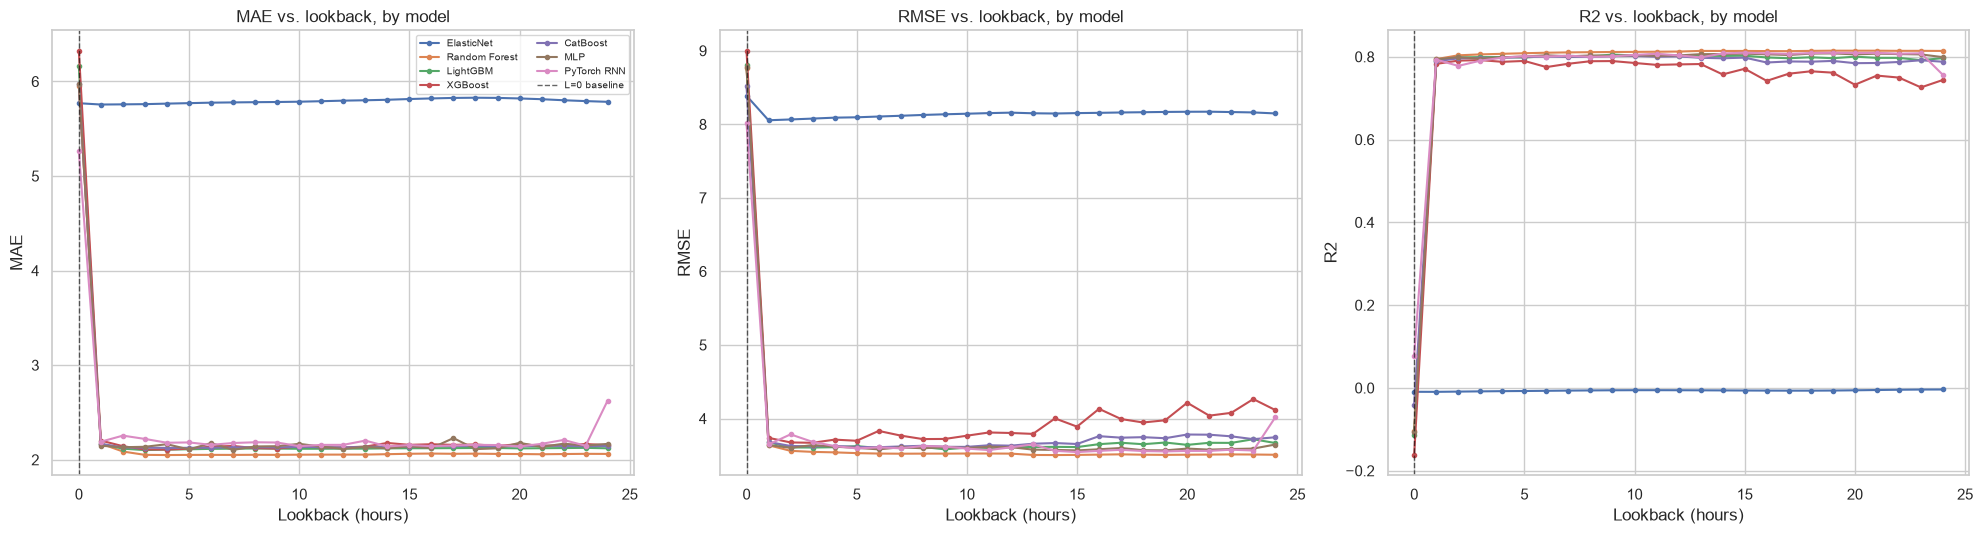

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, metric in zip(axes, ["MAE", "RMSE", "R2"]):
    for model_name in experiment1_results_df["model"].unique():
        sub = experiment1_results_df[experiment1_results_df["model"] == model_name].sort_values("lookback")
        ax.plot(sub["lookback"], sub[metric], marker="o", markersize=3, label=model_name)
    ax.axvline(0, color="black", linestyle="--", linewidth=1, alpha=0.6, label="L=0 baseline")
    ax.set_xlabel("Lookback (hours)")
    ax.set_ylabel(metric)
    ax.set_title(f"{metric} vs. lookback, by model")
axes[0].legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

## Best Lookback Hours

In [41]:
baseline_rows = experiment1_results_df[experiment1_results_df["lookback"] == 0].set_index("model")

best_overall_row = experiment1_results_df.loc[experiment1_results_df["RMSE"].idxmin()]
print("=== Best overall (lookback, model) by RMSE ===")
print(best_overall_row[["lookback", "model", "MAE", "RMSE", "R2"]])

print("\n=== Best lookback PER MODEL, vs. that model's own L=0 baseline ===")
best_per_model_rows = []
for model_name, sub in experiment1_results_df.groupby("model"):
    best_row = sub.loc[sub["RMSE"].idxmin()]
    base = baseline_rows.loc[model_name] if model_name in baseline_rows.index else None
    rmse_change_pct = (
        100 * (best_row["RMSE"] - base["RMSE"]) / base["RMSE"] if base is not None else np.nan
    )
    best_per_model_rows.append({
        "model": model_name,
        "best_lookback": best_row["lookback"],
        "MAE": best_row["MAE"], "RMSE": best_row["RMSE"], "R2": best_row["R2"],
        "L0_RMSE": base["RMSE"] if base is not None else np.nan,
        "RMSE_change_vs_L0_pct": rmse_change_pct,
    })
best_per_model_df = pd.DataFrame(best_per_model_rows).sort_values("RMSE")
best_per_model_df.style.format({
    "MAE": "{:.3f}", "RMSE": "{:.3f}", "R2": "{:.3f}", "L0_RMSE": "{:.3f}",
    "RMSE_change_vs_L0_pct": "{:+.2f}%",
})

=== Best overall (lookback, model) by RMSE ===
lookback               14
model       Random Forest
MAE              2.058346
RMSE             3.503395
R2               0.813923
Name: 99, dtype: object

=== Best lookback PER MODEL, vs. that model's own L=0 baseline ===


,model,best_lookback,MAE,RMSE,R2,L0_RMSE,RMSE_change_vs_L0_pct
5,Random Forest,14,2.058,3.503,0.814,8.769,-60.05%
4,PyTorch RNN,15,2.155,3.544,0.810,8.016,-55.79%
3,MLP,15,2.142,3.566,0.807,8.778,-59.37%
2,LightGBM,9,2.117,3.581,0.805,8.811,-59.35%
0,CatBoost,6,2.127,3.610,0.800,8.521,-57.64%
6,XGBoost,3,2.109,3.670,0.792,9.000,-59.22%
1,ElasticNet,1,5.756,8.054,-0.010,8.388,-3.97%


## Average RMSE by Lookback Hours

In [43]:
lookback_mean_rmse = experiment1_results_df.groupby("lookback")["RMSE"].mean().sort_values()
print("Mean RMSE by lookback (lower is better, averaged across all 7 models):")
print(lookback_mean_rmse)

SELECTED_LOOKBACK = int(lookback_mean_rmse.idxmin())
print(f"\nLookback selected to carry into Experiment 2 (winsorization): L={SELECTED_LOOKBACK}")

Mean RMSE by lookback (lower is better, averaged across all 7 models):
lookback
5     4.250782
9     4.258197
4     4.260388
7     4.261497
8     4.262056
10    4.263213
3     4.263545
6     4.265403
11    4.271197
2     4.274259
15    4.274643
13    4.277264
12    4.278016
14    4.295290
1     4.296456
18    4.305949
19    4.310814
17    4.321395
21    4.329483
22    4.334757
16    4.335659
20    4.352591
23    4.361500
24    4.406490
0     8.611806
Name: RMSE, dtype: float64

Lookback selected to carry into Experiment 2 (winsorization): L=5


# Winsorization at the Selected Temporal Configuration

Winsorization thresholds are computed on training data only.

In [45]:
WINSOR_PERCENTILES = [0.90, 0.95, 0.97, 0.98, 0.99, 0.995]

# Rebuild the selected lookback's dataset once. It was computed above, but is
# rebuilt here so this section can run independently.
if SELECTED_LOOKBACK == 0:
    sel_eligible_df, sel_summary = build_lookback_dataset(
        per_location_frames, TARGET, FEATURE_COLS_FOR_TEMPORAL, SELECTED_LOOKBACK
    )
    sel_seq_array = None
else:
    sel_eligible_df, sel_summary, sel_seq_array = build_lookback_dataset(
        per_location_frames, TARGET, FEATURE_COLS_FOR_TEMPORAL, SELECTED_LOOKBACK, build_sequences=True
    )

sel_train_block, sel_test_block, sel_train_mask = split_eligible(sel_eligible_df, SPLIT_BOUNDARY_TIME)
X_train_sel, X_test_sel, norm_stats_sel = build_processed_features_temporal(
    sel_train_block, sel_test_block, SELECTED_LOOKBACK
)
non_pm_features = [c for c in FEATURE_COLS_FOR_TEMPORAL if c != TARGET]
static_cols_sel = [c for c in X_train_sel.columns if not c.startswith("lag_")]

if SELECTED_LOOKBACK > 0:
    sel_seq_train_raw = sel_seq_array[np.where(sel_train_mask)[0]]
    sel_seq_test_raw = sel_seq_array[np.where(~sel_train_mask)[0]]
else:
    sel_seq_train_raw = sel_seq_test_raw = None

print(f"Experiment 2 running at SELECTED_LOOKBACK={SELECTED_LOOKBACK}  "
      f"(train n={len(sel_train_block):,}, test n={len(sel_test_block):,})")

Experiment 2 running at SELECTED_LOOKBACK=5  (train n=1,070,724, test n=181,794)


In [46]:
experiment2_results = []
experiment2_threshold_summary = []

for percentile in WINSOR_PERCENTILES:
    threshold = sel_train_block[TARGET].quantile(percentile)
    n_train_affected = (sel_train_block[TARGET] >= threshold).sum()
    n_test_affected = (sel_test_block[TARGET] >= threshold).sum()
    pct_affected = 100 * (n_train_affected + n_test_affected) / (len(sel_train_block) + len(sel_test_block))

    experiment2_threshold_summary.append({
        "winsorization_percentile": percentile, "winsorization_threshold": threshold,
        "train_observations_affected": n_train_affected, "test_observations_affected": n_test_affected,
        "pct_affected": pct_affected,
    })

    y_train_w = sel_train_block[TARGET].clip(upper=threshold).to_numpy()
    y_test_w = sel_test_block[TARGET].clip(upper=threshold).to_numpy()

    print("=" * 78)
    print(f"Percentile {percentile:.1%} -> threshold={threshold:.2f} | "
          f"train affected={n_train_affected} | test affected={n_test_affected} ({pct_affected:.3f}%)")
    print("=" * 78)

    # Six flattened models
    models = get_experiment1_models()
    for model_name, model in models.items():
        model.fit(X_train_sel, y_train_w)
        y_pred = model.predict(X_test_sel)
        metrics = evaluate(y_test_w, y_pred)
        metrics.update({
            "winsorization_percentile": percentile, "winsorization_threshold": threshold,
            "model": model_name, "lookback": SELECTED_LOOKBACK,
        })
        experiment2_results.append(metrics)
        print(f"  {model_name:<14} MAE={metrics['MAE']:.3f}  RMSE={metrics['RMSE']:.3f}  R2={metrics['R2']:.3f}")

    # PyTorch RNN
    if SELECTED_LOOKBACK > 0:
        seq_train_norm_w, seq_test_norm_w = normalize_sequence_array(
            sel_seq_train_raw, sel_seq_test_raw, non_pm_features, CONTINUOUS_FEATURES,
            norm_stats_sel["_pm_lag"]["mean"], norm_stats_sel["_pm_lag"]["denom"], norm_stats_sel,
        )
    else:
        seq_train_norm_w = seq_test_norm_w = None

    X_static_train_sel = X_train_sel[static_cols_sel].to_numpy()
    X_static_test_sel = X_test_sel[static_cols_sel].to_numpy()
    rnn_model_w, y_pred_rnn_w = train_rnn(
        X_static_train_sel, seq_train_norm_w, y_train_w, X_static_test_sel, seq_test_norm_w,
    )
    metrics = evaluate(y_test_w, y_pred_rnn_w)
    metrics.update({
        "winsorization_percentile": percentile, "winsorization_threshold": threshold,
        "model": "PyTorch RNN", "lookback": SELECTED_LOOKBACK,
    })
    experiment2_results.append(metrics)
    print(f"  {'PyTorch RNN':<14} MAE={metrics['MAE']:.3f}  RMSE={metrics['RMSE']:.3f}  R2={metrics['R2']:.3f}")

experiment2_results_df = pd.DataFrame(experiment2_results)[
    ["winsorization_percentile", "winsorization_threshold", "lookback", "model", "MAE", "MSE", "RMSE", "R2"]
]
experiment2_threshold_summary_df = pd.DataFrame(experiment2_threshold_summary)

Percentile 90.0% -> threshold=19.79 | train affected=107073 | test affected=15146 (9.758%)
  ElasticNet     MAE=4.726  RMSE=5.708  R2=-0.002
  Random Forest  MAE=1.676  RMSE=2.535  R2=0.802
  LightGBM       MAE=1.702  RMSE=2.540  R2=0.801
  XGBoost        MAE=1.702  RMSE=2.538  R2=0.802
  CatBoost       MAE=1.716  RMSE=2.555  R2=0.799
  MLP            MAE=1.714  RMSE=2.583  R2=0.795
    RNN epoch 1/8  mean batch MSE = 36.5669
    RNN epoch 2/8  mean batch MSE = 18.7804
    RNN epoch 3/8  mean batch MSE = 9.7035
    RNN epoch 4/8  mean batch MSE = 9.1017
    RNN epoch 5/8  mean batch MSE = 8.6944
    RNN epoch 6/8  mean batch MSE = 8.1673
    RNN epoch 7/8  mean batch MSE = 7.4189
    RNN epoch 8/8  mean batch MSE = 6.5399
  PyTorch RNN    MAE=2.241  RMSE=3.057  R2=0.712
Percentile 95.0% -> threshold=27.09 | train affected=53549 | test affected=6500 (4.794%)
  ElasticNet     MAE=5.236  RMSE=6.652  R2=-0.003
  Random Forest  MAE=1.853  RMSE=2.867  R2=0.814
  LightGBM       MAE=1.881  RMS

## Winsorization Results

In [50]:
experiment2_threshold_summary_df.style.format({
    "winsorization_percentile": "{:.1%}", "winsorization_threshold": "{:.2f}", "pct_affected": "{:.3f}",
})

,winsorization_percentile,winsorization_threshold,train_observations_affected,test_observations_affected,pct_affected
0,90.0%,19.79,107073,15146,9.758
1,95.0%,27.09,53549,6500,4.794
2,97.0%,33.10,32130,3423,2.839
3,98.0%,38.00,21642,1979,1.886
4,99.0%,46.20,10715,801,0.919
5,99.5%,54.57,5354,387,0.458


In [51]:
experiment2_results_df.style.format({
    "winsorization_percentile": "{:.1%}", "winsorization_threshold": "{:.2f}",
    "MAE": "{:.3f}", "MSE": "{:.3f}", "RMSE": "{:.3f}", "R2": "{:.3f}",
}).background_gradient(subset=["RMSE"], cmap="Reds").background_gradient(subset=["R2"], cmap="Greens")

,winsorization_percentile,winsorization_threshold,lookback,model,MAE,MSE,RMSE,R2
0,90.0%,19.79,5,ElasticNet,4.726,32.576,5.708,-0.002
1,90.0%,19.79,5,Random Forest,1.676,6.428,2.535,0.802
2,90.0%,19.79,5,LightGBM,1.702,6.452,2.540,0.801
3,90.0%,19.79,5,XGBoost,1.702,6.442,2.538,0.802
4,90.0%,19.79,5,CatBoost,1.716,6.529,2.555,0.799
5,90.0%,19.79,5,MLP,1.714,6.674,2.583,0.795
6,90.0%,19.79,5,PyTorch RNN,2.241,9.344,3.057,0.712
7,95.0%,27.09,5,ElasticNet,5.236,44.255,6.652,-0.003
8,95.0%,27.09,5,Random Forest,1.853,8.220,2.867,0.814
9,95.0%,27.09,5,LightGBM,1.881,8.249,2.872,0.813


## Winsorization Plots

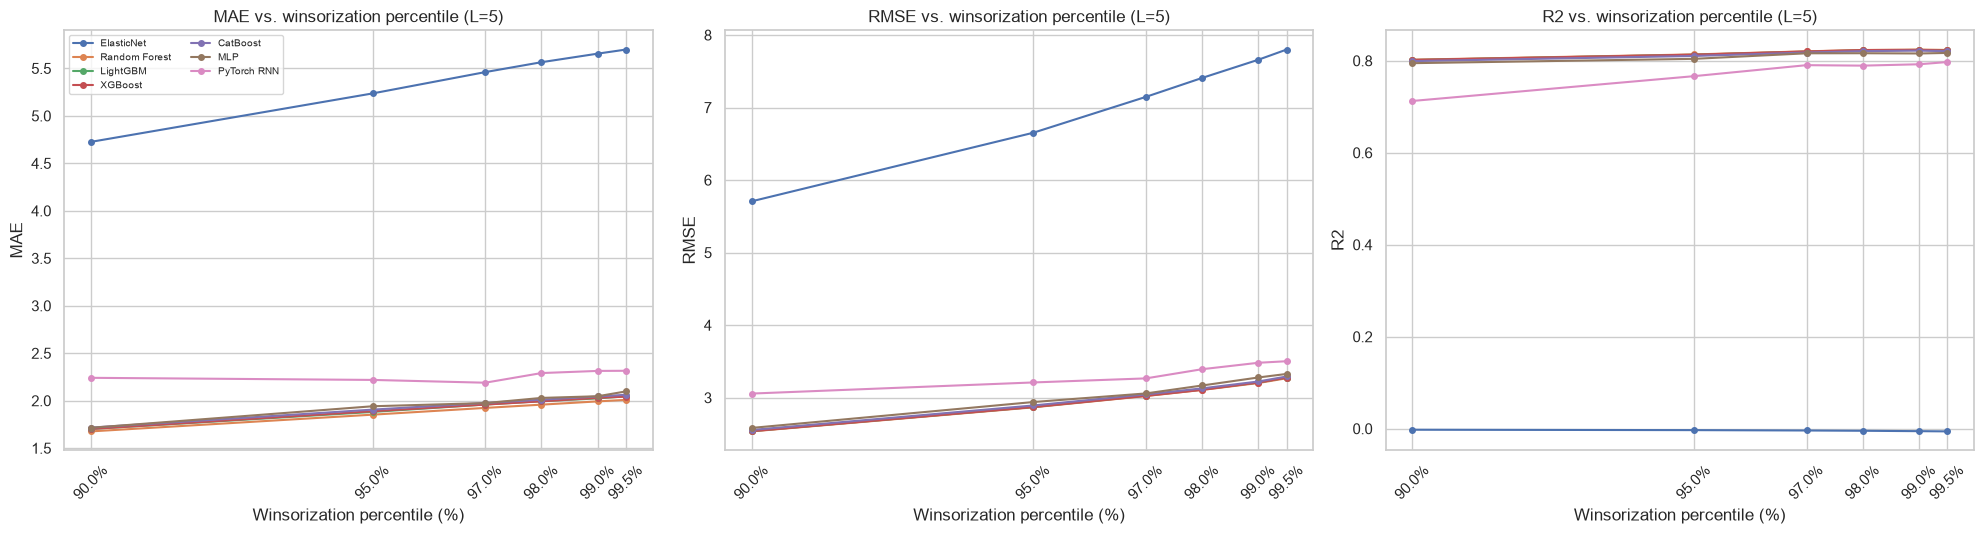

Best winsorization overall (by RMSE):
winsorization_percentile              0.9
model                       Random Forest
MAE                              1.676413
RMSE                             2.535384
R2                               0.802213
Name: 1, dtype: object

Best winsorization PER MODEL:


,model,winsorization_percentile,MAE,RMSE,R2
1,Random Forest,0.9,1.676413,2.535384,0.802213
3,XGBoost,0.9,1.701708,2.538176,0.801777
2,LightGBM,0.9,1.701916,2.540038,0.801486
4,CatBoost,0.9,1.716499,2.555271,0.799098
5,MLP,0.9,1.714290,2.583344,0.794659
6,PyTorch RNN,0.9,2.240626,3.056811,0.712493
0,ElasticNet,0.9,4.726373,5.707551,-0.002329


In [53]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, metric in zip(axes, ["MAE", "RMSE", "R2"]):
    for model_name in experiment2_results_df["model"].unique():
        sub = experiment2_results_df[experiment2_results_df["model"] == model_name].sort_values("winsorization_percentile")
        ax.plot(sub["winsorization_percentile"] * 100, sub[metric], marker="o", markersize=4, label=model_name)
    ax.set_xlabel("Winsorization percentile (%)")
    ax.set_ylabel(metric)
    ax.set_title(f"{metric} vs. winsorization percentile (L={SELECTED_LOOKBACK})")
    ax.set_xticks([p * 100 for p in WINSOR_PERCENTILES])
    ax.set_xticklabels([f"{p:.1%}" for p in WINSOR_PERCENTILES], rotation=45)
axes[0].legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

print("Best winsorization overall (by RMSE):")
print(experiment2_results_df.loc[experiment2_results_df["RMSE"].idxmin(),
      ["winsorization_percentile", "model", "MAE", "RMSE", "R2"]])

print("\nBest winsorization PER MODEL:")
best_winsor_per_model = experiment2_results_df.loc[
    experiment2_results_df.groupby("model")["RMSE"].idxmin()
][["model", "winsorization_percentile", "MAE", "RMSE", "R2"]].sort_values("RMSE")
best_winsor_per_model

## Final Comparison

In [55]:
no_winsor_row = experiment2_results_df[experiment2_results_df["winsorization_percentile"] == WINSOR_PERCENTILES[0]]
original_baseline_row = experiment1_results_df[experiment1_results_df["lookback"] == 0].loc[
    experiment1_results_df[experiment1_results_df["lookback"] == 0]["RMSE"].idxmin()
]
best_temporal_row = experiment1_results_df.loc[experiment1_results_df["RMSE"].idxmin()]
best_temporal_winsor_row = experiment2_results_df.loc[experiment2_results_df["RMSE"].idxmin()]

final_comparison = pd.DataFrame([
    {
        "stage": "Original baseline (L=0, no winsorization)",
        "model": original_baseline_row["model"], "lookback": 0, "winsorization": "none",
        "MAE": original_baseline_row["MAE"], "RMSE": original_baseline_row["RMSE"], "R2": original_baseline_row["R2"],
    },
    {
        "stage": "Best temporal model (Experiment 1, no winsorization)",
        "model": best_temporal_row["model"], "lookback": best_temporal_row["lookback"], "winsorization": "none",
        "MAE": best_temporal_row["MAE"], "RMSE": best_temporal_row["RMSE"], "R2": best_temporal_row["R2"],
    },
    {
        "stage": "Best temporal + winsorization model (Experiment 2)",
        "model": best_temporal_winsor_row["model"], "lookback": SELECTED_LOOKBACK,
        "winsorization": f"{best_temporal_winsor_row['winsorization_percentile']:.1%}",
        "MAE": best_temporal_winsor_row["MAE"], "RMSE": best_temporal_winsor_row["RMSE"], "R2": best_temporal_winsor_row["R2"],
    },
])
final_comparison

,stage,model,lookback,winsorization,MAE,RMSE,R2
0,"Original baseline (L=0, no winsorization)",PyTorch RNN,0,none,5.265819,8.015993,0.078073
1,"Best temporal model (Experiment 1, no winsoriz...",Random Forest,14,none,2.058346,3.503395,0.813923
2,Best temporal + winsorization model (Experimen...,Random Forest,5,90.0%,1.676413,2.535384,0.802213


In [109]:
# Uses best_per_model_df from Experiment 1 (model -> its own best lookback by RMSE).
# Each model is winsorized and evaluated at its own best lookback, not a shared one.

WINSOR_PERCENTILES = [0.90, 0.95, 0.97, 0.98, 0.99, 0.995]

best_lookback_by_model = best_per_model_df.set_index("model")["best_lookback"].to_dict()
print("Best lookback per model (from Experiment 1):")
for m, L in best_lookback_by_model.items():
    print(f"  {m:<14} L={L}")

non_pm_features = [c for c in FEATURE_COLS_FOR_TEMPORAL if c != TARGET]

# Cache built datasets per distinct lookback so repeated values of L are not rebuilt.
_lookback_cache = {}

def get_lookback_bundle(L):
    if L not in _lookback_cache:
        if L == 0:
            eligible_df, summary = build_lookback_dataset(per_location_frames, TARGET, FEATURE_COLS_FOR_TEMPORAL, L)
            seq_array = None
        else:
            eligible_df, summary, seq_array = build_lookback_dataset(
                per_location_frames, TARGET, FEATURE_COLS_FOR_TEMPORAL, L, build_sequences=True
            )
        train_block, test_block, train_mask = split_eligible(eligible_df, SPLIT_BOUNDARY_TIME)
        X_train_L, X_test_L, norm_stats_L = build_processed_features_temporal(train_block, test_block, L)
        static_cols = [c for c in X_train_L.columns if not c.startswith("lag_")]
        _lookback_cache[L] = dict(
            train_block=train_block, test_block=test_block, train_mask=train_mask,
            X_train=X_train_L, X_test=X_test_L, norm_stats=norm_stats_L,
            seq_array=seq_array, static_cols=static_cols,
        )
    return _lookback_cache[L]

experiment2_permodel_results = []
experiment2_permodel_threshold_summary = []

for model_name, L in best_lookback_by_model.items():
    L = int(L)
    bundle = get_lookback_bundle(L)
    train_block, test_block = bundle["train_block"], bundle["test_block"]
    X_train_L, X_test_L = bundle["X_train"], bundle["X_test"]
    norm_stats_L = bundle["norm_stats"]

    print(f"\n### {model_name}  (best lookback L={L}, train n={len(train_block):,}, test n={len(test_block):,})")

    for percentile in WINSOR_PERCENTILES:
        # Winsorization threshold fit on this model's training split only.
        threshold = train_block[TARGET].quantile(percentile)
        n_train_affected = (train_block[TARGET] >= threshold).sum()
        n_test_affected = (test_block[TARGET] >= threshold).sum()
        pct_affected = 100 * (n_train_affected + n_test_affected) / (len(train_block) + len(test_block))

        experiment2_permodel_threshold_summary.append({
            "model": model_name, "lookback": L,
            "winsorization_percentile": percentile, "winsorization_threshold": threshold,
            "train_observations_affected": n_train_affected,
            "test_observations_affected": n_test_affected,
            "pct_affected": pct_affected,
        })

        y_train_w = train_block[TARGET].clip(upper=threshold).to_numpy()
        y_test_w = test_block[TARGET].clip(upper=threshold).to_numpy()

        if model_name == "PyTorch RNN":
            if L > 0:
                seq_array = bundle["seq_array"]
                train_mask = bundle["train_mask"]
                seq_train_raw = seq_array[np.where(train_mask)[0]]
                seq_test_raw = seq_array[np.where(~train_mask)[0]]
                seq_train_norm, seq_test_norm = normalize_sequence_array(
                    seq_train_raw, seq_test_raw, non_pm_features, CONTINUOUS_FEATURES,
                    norm_stats_L["_pm_lag"]["mean"], norm_stats_L["_pm_lag"]["denom"], norm_stats_L,
                )
            else:
                seq_train_norm = seq_test_norm = None
            static_cols = bundle["static_cols"]
            X_static_train = X_train_L[static_cols].to_numpy()
            X_static_test = X_test_L[static_cols].to_numpy()
            _, y_pred = train_rnn(X_static_train, seq_train_norm, y_train_w, X_static_test, seq_test_norm)
        else:
            model = get_experiment1_models()[model_name]
            model.fit(X_train_L, y_train_w)
            y_pred = model.predict(X_test_L)

        metrics = evaluate(y_test_w, y_pred)
        metrics.update({
            "model": model_name, "lookback": L,
            "winsorization_percentile": percentile, "winsorization_threshold": threshold,
        })
        experiment2_permodel_results.append(metrics)
        print(f"  pct={percentile:.1%}  MAE={metrics['MAE']:.3f}  RMSE={metrics['RMSE']:.3f}  R2={metrics['R2']:.3f}")

experiment2_permodel_results_df = pd.DataFrame(experiment2_permodel_results)[
    ["model", "lookback", "winsorization_percentile", "winsorization_threshold", "MAE", "MSE", "RMSE", "R2"]
]
experiment2_permodel_threshold_summary_df = pd.DataFrame(experiment2_permodel_threshold_summary)

print("\nBest winsorization percentile PER MODEL (at that model's own best lookback):")
best_winsor_permodel = experiment2_permodel_results_df.loc[
    experiment2_permodel_results_df.groupby("model")["RMSE"].idxmin()
][["model", "lookback", "winsorization_percentile", "MAE", "RMSE", "R2"]].sort_values("RMSE")
print(best_winsor_permodel)

Best lookback per model (from Experiment 1):
  Random Forest  L=14
  PyTorch RNN    L=15
  MLP            L=15
  LightGBM       L=9
  CatBoost       L=6
  XGBoost        L=3
  ElasticNet     L=1

### Random Forest  (best lookback L=14, train n=858,789, test n=165,369)
  pct=90.0%  MAE=1.689  RMSE=2.540  R2=0.807
  pct=95.0%  MAE=1.877  RMSE=2.887  R2=0.819
  pct=97.0%  MAE=1.943  RMSE=3.031  R2=0.825
  pct=98.0%  MAE=1.975  RMSE=3.110  R2=0.827
  pct=99.0%  MAE=2.006  RMSE=3.201  R2=0.828
  pct=99.5%  MAE=2.022  RMSE=3.269  R2=0.827

### PyTorch RNN  (best lookback L=15, train n=838,744, test n=163,732)
    RNN epoch 1/8  mean batch MSE = 40.0028
    RNN epoch 2/8  mean batch MSE = 18.9678
    RNN epoch 3/8  mean batch MSE = 10.4163
    RNN epoch 4/8  mean batch MSE = 7.4944
    RNN epoch 5/8  mean batch MSE = 5.7468
    RNN epoch 6/8  mean batch MSE = 4.6777
    RNN epoch 7/8  mean batch MSE = 4.1836
    RNN epoch 8/8  mean batch MSE = 3.9110
  pct=90.0%  MAE=1.801  RMSE=2.638  R2=0.7

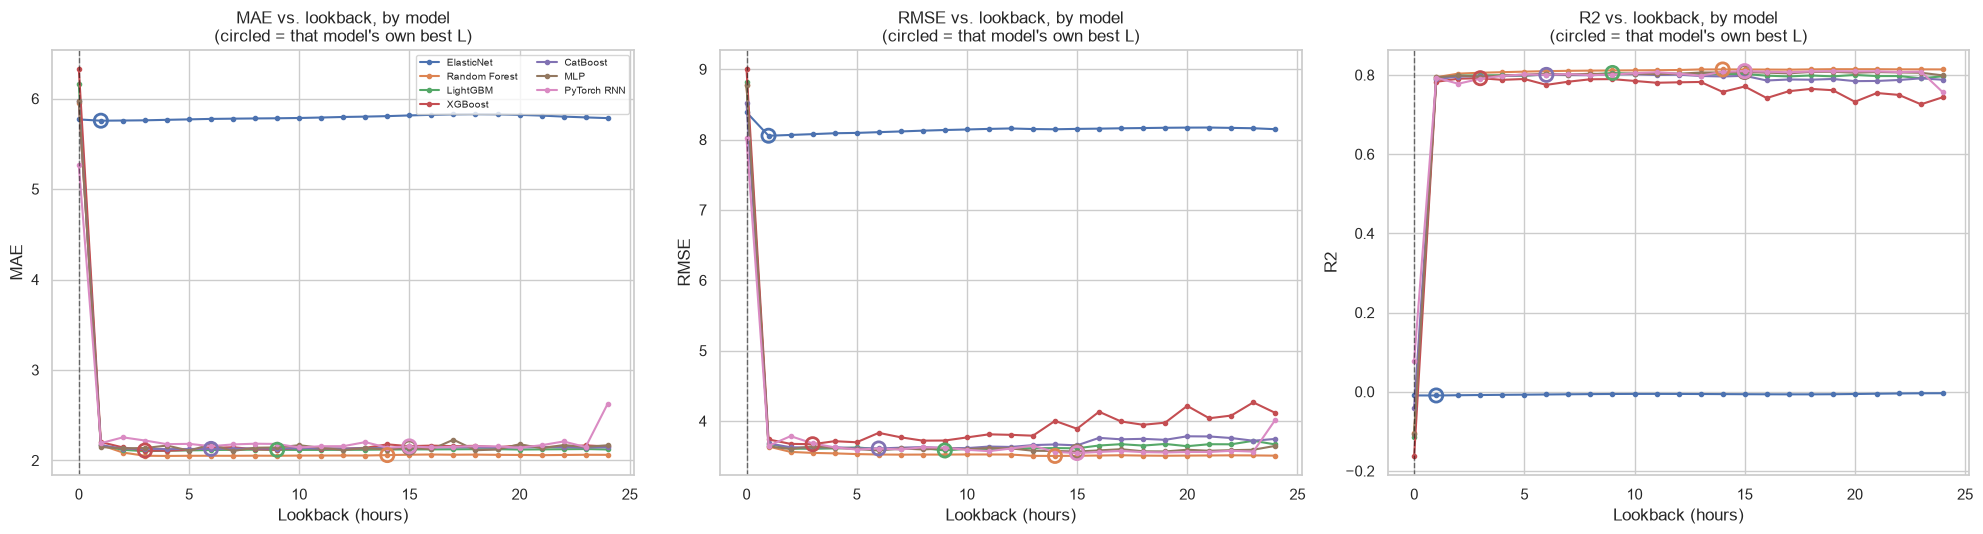

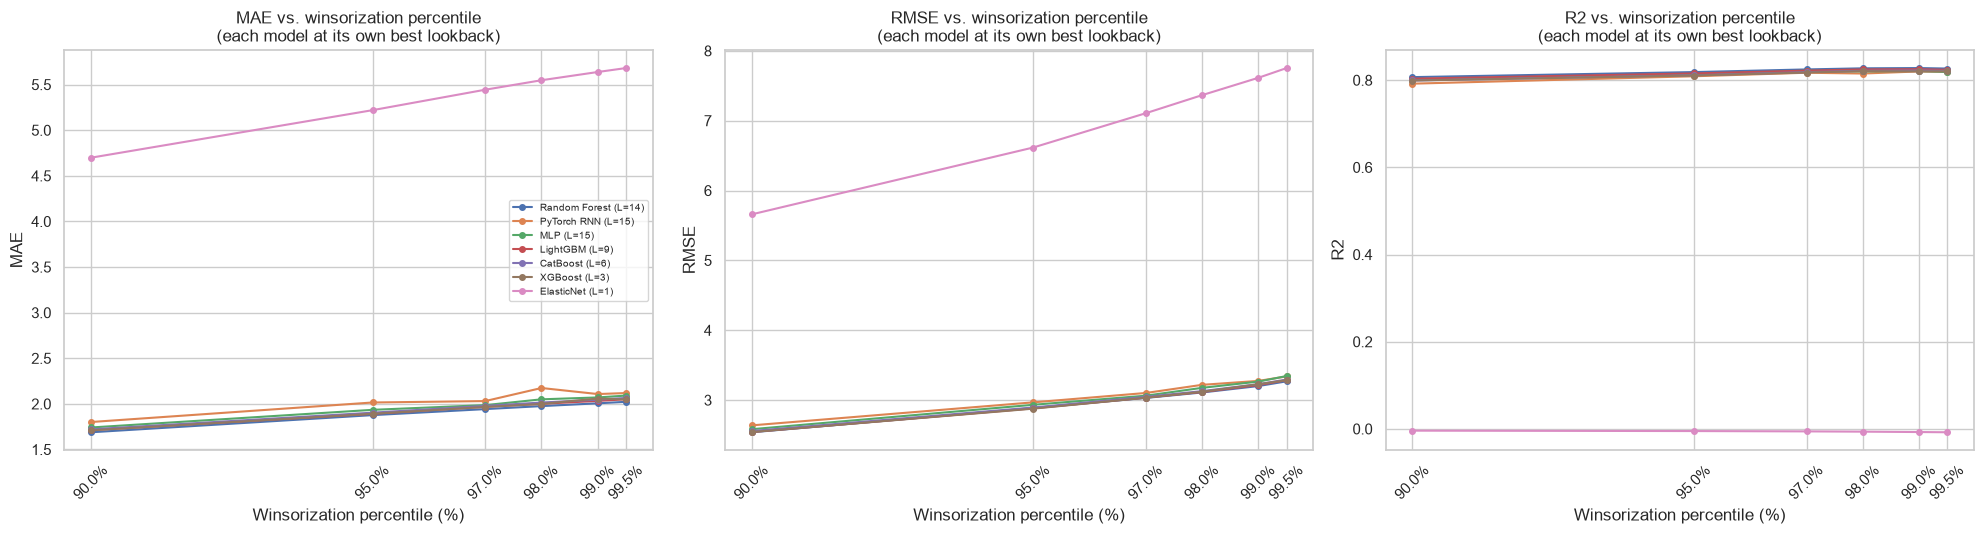

In [110]:
# Plot 1: performance vs. lookback, one line per model, each model's best L circled
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, metric in zip(axes, ["MAE", "RMSE", "R2"]):
    for model_name in experiment1_results_df["model"].unique():
        sub = experiment1_results_df[experiment1_results_df["model"] == model_name].sort_values("lookback")
        line, = ax.plot(sub["lookback"], sub[metric], marker="o", markersize=3, label=model_name)
        best_L = best_lookback_by_model[model_name]
        best_val = sub.loc[sub["lookback"] == best_L, metric].values[0]
        ax.scatter([best_L], [best_val], s=90, facecolors="none",
                   edgecolors=line.get_color(), linewidths=2, zorder=5)
    ax.axvline(0, color="black", linestyle="--", linewidth=1, alpha=0.5)
    ax.set_xlabel("Lookback (hours)")
    ax.set_ylabel(metric)
    ax.set_title(f"{metric} vs. lookback, by model\n(circled = that model's own best L)")
axes[0].legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

# Plot 2: performance vs. winsorization percentile, one line per model
# Each model is plotted at its own best lookback (from experiment2_permodel_results_df).
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, metric in zip(axes, ["MAE", "RMSE", "R2"]):
    for model_name in experiment2_permodel_results_df["model"].unique():
        sub = experiment2_permodel_results_df[
            experiment2_permodel_results_df["model"] == model_name
        ].sort_values("winsorization_percentile")
        L_used = sub["lookback"].iloc[0]
        ax.plot(sub["winsorization_percentile"] * 100, sub[metric], marker="o", markersize=4,
                label=f"{model_name} (L={L_used})")
    ax.set_xlabel("Winsorization percentile (%)")
    ax.set_ylabel(metric)
    ax.set_title(f"{metric} vs. winsorization percentile\n(each model at its own best lookback)")
    ax.set_xticks([p * 100 for p in WINSOR_PERCENTILES])
    ax.set_xticklabels([f"{p:.1%}" for p in WINSOR_PERCENTILES], rotation=45)
axes[0].legend(fontsize=7, ncol=1)
fig.tight_layout()
plt.show()

In [113]:
# Hyperparameter tuning per model and winsorization percentile
# Each model is tuned at its own best lookback (best_lookback_by_model, from Experiment 1).
# The sklearn-style models and the MLP use RandomizedSearchCV with TimeSeriesSplit.
# The RNN is not an sklearn estimator, so it uses a chronological holdout search (see tune_rnn).

from sklearn.neural_network import MLPRegressor

TUNING_SEARCH_SAMPLE_SIZE = 100_000   # rows used only for the search (sklearn models)
N_TIME_SERIES_SPLITS = 4
N_RANDOM_SEARCH_ITER = 8

param_distributions = {
    "ElasticNet": {
        "alpha": [0.001, 0.01, 0.1, 0.5, 1.0, 5.0],
        "l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9, 1.0],
    },
    "Random Forest": {
        "n_estimators": [150, 250, 350],
        "max_depth": [8, 12, 16, None],
        "min_samples_leaf": [5, 20, 50],
    },
    "LightGBM": {
        "n_estimators": [200, 400, 600],
        "learning_rate": [0.02, 0.05, 0.1],
        "num_leaves": [15, 31, 63],
    },
    "XGBoost": {
        "n_estimators": [200, 400, 600],
        "learning_rate": [0.02, 0.05, 0.1],
        "max_depth": [4, 6, 8],
    },
    "CatBoost": {
        "iterations": [200, 400, 600],
        "learning_rate": [0.02, 0.05, 0.1],
        "depth": [4, 6, 8],
    },
    # MLP grid. Widen or narrow as needed.
    "MLP": {
        "hidden_layer_sizes": [(32,), (64, 32), (64, 32, 16), (128, 64)],
        "alpha": [0.0001, 0.001, 0.01],
        "learning_rate_init": [0.001, 0.005, 0.01],
    },
}

def get_unfitted_model(model_name):
    if model_name == "ElasticNet":
        return ElasticNet(random_state=RANDOM_STATE, max_iter=5000)
    if model_name == "Random Forest":
        return RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)
    if model_name == "LightGBM":
        return lgb.LGBMRegressor(random_state=RANDOM_STATE, verbosity=-1)
    if model_name == "XGBoost":
        return xgb.XGBRegressor(random_state=RANDOM_STATE, verbosity=0,
                                 objective="reg:squarederror", tree_method="hist")
    if model_name == "CatBoost":
        return CatBoostRegressor(random_state=RANDOM_STATE, verbose=0)
    if model_name == "MLP":
        return MLPRegressor(random_state=RANDOM_STATE, max_iter=500, early_stopping=True)
    raise ValueError(model_name)


# RNN: manual hyperparameter grid
RNN_PARAM_GRID = [
    {"hidden_size": 16, "num_layers": 1, "rnn_type": "GRU",  "lr": 1e-3},
    {"hidden_size": 32, "num_layers": 1, "rnn_type": "GRU",  "lr": 1e-3},
    {"hidden_size": 32, "num_layers": 2, "rnn_type": "GRU",  "lr": 1e-3},
    {"hidden_size": 32, "num_layers": 1, "rnn_type": "LSTM", "lr": 1e-3},
    {"hidden_size": 64, "num_layers": 1, "rnn_type": "GRU",  "lr": 5e-4},
    {"hidden_size": 64, "num_layers": 2, "rnn_type": "LSTM", "lr": 5e-4},
]
RNN_SEARCH_EPOCHS = 6      # short training runs used only to rank candidates
RNN_FINAL_EPOCHS = 15      # full training run for the winning config's final fit
RNN_VALIDATION_FRACTION = 0.15  # most recent slice of train held out as a chronological validation fold


def train_rnn_configurable(X_static_train, X_seq_train, y_train, X_static_test, X_seq_test,
                            hidden_size=32, num_layers=1, rnn_type="GRU", lr=1e-3,
                            epochs=RNN_EPOCHS, batch_size=RNN_BATCH_SIZE, seed=RANDOM_STATE, verbose=True):
    torch.manual_seed(seed)
    static_dim = X_static_train.shape[1]
    seq_feature_dim = X_seq_train.shape[2] if X_seq_train is not None else None

    model = PM25RNN(static_dim=static_dim, seq_feature_dim=seq_feature_dim,
                     hidden_size=hidden_size, num_layers=num_layers, rnn_type=rnn_type).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()

    xs_t = torch.tensor(X_static_train, dtype=torch.float32)
    y_t = torch.tensor(y_train, dtype=torch.float32)
    if X_seq_train is not None:
        xq_t = torch.tensor(X_seq_train, dtype=torch.float32)
        dataset = TensorDataset(xs_t, xq_t, y_t)
    else:
        dataset = TensorDataset(xs_t, y_t)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

    model.train()
    for epoch in range(epochs):
        total_loss, n_batches = 0.0, 0
        for batch in loader:
            optimizer.zero_grad()
            if X_seq_train is not None:
                xs_b, xq_b, y_b = batch
                pred = model(xs_b.to(DEVICE), xq_b.to(DEVICE))
            else:
                xs_b, y_b = batch
                pred = model(xs_b.to(DEVICE))
            loss = loss_fn(pred, y_b.to(DEVICE))
            loss.backward()
            optimizer.step()
            total_loss += loss.item(); n_batches += 1
        if verbose:
            print(f"        epoch {epoch + 1}/{epochs}  mean batch MSE={total_loss / n_batches:.4f}")

    model.eval()
    with torch.no_grad():
        xs_test_t = torch.tensor(X_static_test, dtype=torch.float32).to(DEVICE)
        if X_seq_test is not None:
            xq_test_t = torch.tensor(X_seq_test, dtype=torch.float32).to(DEVICE)
            y_pred = model(xs_test_t, xq_test_t).cpu().numpy()
        else:
            y_pred = model(xs_test_t).cpu().numpy()
    return model, y_pred


def tune_rnn(X_static_train_full, X_seq_train_full, y_train_full,
             param_grid=RNN_PARAM_GRID, val_fraction=RNN_VALIDATION_FRACTION):
    """Chronological holdout search: the most recent `val_fraction` of the
    (already chronologically ordered) training rows becomes a validation fold.
    The real test set is never used. Returns the winning param dict."""
    n = len(y_train_full)
    n_val = max(1, int(n * val_fraction))
    n_fit = n - n_val

    Xs_fit, Xs_val = X_static_train_full[:n_fit], X_static_train_full[n_fit:]
    y_fit, y_val = y_train_full[:n_fit], y_train_full[n_fit:]
    if X_seq_train_full is not None:
        Xq_fit, Xq_val = X_seq_train_full[:n_fit], X_seq_train_full[n_fit:]
    else:
        Xq_fit = Xq_val = None

    best_params, best_rmse = None, np.inf
    for params in param_grid:
        _, y_val_pred = train_rnn_configurable(
            Xs_fit, Xq_fit, y_fit, Xs_val, Xq_val, epochs=RNN_SEARCH_EPOCHS, verbose=False, **params
        )
        rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))
        print(f"      RNN candidate {params} -> val RMSE={rmse:.4f}")
        if rmse < best_rmse:
            best_rmse, best_params = rmse, params

    print(f"      RNN best config: {best_params}  (val RMSE={best_rmse:.4f})")
    return best_params


# Main tuning loop: every model at every winsorization percentile
tuned_permodel_results = []
tuned_permodel_models = {}
best_params_by_model_pct = {}

tscv = TimeSeriesSplit(n_splits=N_TIME_SERIES_SPLITS)

for model_name, L in best_lookback_by_model.items():
    L = int(L)
    bundle = get_lookback_bundle(L)
    train_block, test_block = bundle["train_block"], bundle["test_block"]
    X_train_L, X_test_L = bundle["X_train"], bundle["X_test"]
    norm_stats_L = bundle["norm_stats"]

    print(f"\n{'=' * 80}\nTuning {model_name}  (best lookback L={L})\n{'=' * 80}")

    for percentile in WINSOR_PERCENTILES:
        threshold = train_block[TARGET].quantile(percentile)
        y_train_w = train_block[TARGET].clip(upper=threshold).to_numpy()
        y_test_w = test_block[TARGET].clip(upper=threshold).to_numpy()

        print(f"\n-- {model_name} @ {percentile:.1%} (threshold={threshold:.2f}) --")

        if model_name == "PyTorch RNN":
            if L > 0:
                seq_array = bundle["seq_array"]
                train_mask = bundle["train_mask"]
                seq_train_raw = seq_array[np.where(train_mask)[0]]
                seq_test_raw = seq_array[np.where(~train_mask)[0]]
                seq_train_norm, seq_test_norm = normalize_sequence_array(
                    seq_train_raw, seq_test_raw, non_pm_features, CONTINUOUS_FEATURES,
                    norm_stats_L["_pm_lag"]["mean"], norm_stats_L["_pm_lag"]["denom"], norm_stats_L,
                )
            else:
                seq_train_norm = seq_test_norm = None
            static_cols = bundle["static_cols"]
            X_static_train = X_train_L[static_cols].to_numpy()
            X_static_test = X_test_L[static_cols].to_numpy()

            best_params = tune_rnn(X_static_train, seq_train_norm, y_train_w)
            final_params = dict(best_params, epochs=RNN_FINAL_EPOCHS)
            _, y_pred = train_rnn_configurable(
                X_static_train, seq_train_norm, y_train_w, X_static_test, seq_test_norm, **final_params
            )
            best_params_by_model_pct[(model_name, percentile)] = final_params

        else:
            base_model = get_unfitted_model(model_name)
            n_search = min(TUNING_SEARCH_SAMPLE_SIZE, len(X_train_L))
            X_search = X_train_L.iloc[-n_search:]
            y_search = y_train_w[-n_search:]

            search = RandomizedSearchCV(
                base_model, param_distributions=param_distributions[model_name],
                n_iter=N_RANDOM_SEARCH_ITER, cv=tscv, scoring="neg_root_mean_squared_error",
                random_state=RANDOM_STATE, n_jobs=-1,
            )
            search.fit(X_search, y_search)
            best_params_by_model_pct[(model_name, percentile)] = search.best_params_
            print(f"    best_params={search.best_params_}")

            final_model = get_unfitted_model(model_name).set_params(**search.best_params_)
            final_model.fit(X_train_L, y_train_w)
            y_pred = final_model.predict(X_test_L)
            tuned_permodel_models[(model_name, percentile)] = final_model

        metrics = evaluate(y_test_w, y_pred)
        metrics.update({
            "model": model_name, "lookback": L,
            "winsorization_percentile": percentile, "winsorization_threshold": threshold,
        })
        tuned_permodel_results.append(metrics)
        print(f"    MAE={metrics['MAE']:.3f}  RMSE={metrics['RMSE']:.3f}  R2={metrics['R2']:.3f}")

tuned_permodel_results_df = pd.DataFrame(tuned_permodel_results)[
    ["model", "lookback", "winsorization_percentile", "winsorization_threshold", "MAE", "MSE", "RMSE", "R2"]
]

print("\nBest winsorization percentile PER MODEL, after tuning:")
best_tuned_permodel = tuned_permodel_results_df.loc[
    tuned_permodel_results_df.groupby("model")["RMSE"].idxmin()
][["model", "lookback", "winsorization_percentile", "MAE", "RMSE", "R2"]].sort_values("RMSE")
print(best_tuned_permodel)


Tuning Random Forest  (best lookback L=14)

-- Random Forest @ 90.0% (threshold=20.00) --
    best_params={'n_estimators': 250, 'min_samples_leaf': 50, 'max_depth': 12}
    MAE=1.687  RMSE=2.540  R2=0.807

-- Random Forest @ 95.0% (threshold=28.00) --
    best_params={'n_estimators': 250, 'min_samples_leaf': 50, 'max_depth': 12}
    MAE=1.874  RMSE=2.887  R2=0.819

-- Random Forest @ 97.0% (threshold=34.05) --
    best_params={'n_estimators': 250, 'min_samples_leaf': 50, 'max_depth': 12}
    MAE=1.940  RMSE=3.032  R2=0.825

-- Random Forest @ 98.0% (threshold=39.00) --
    best_params={'n_estimators': 250, 'min_samples_leaf': 50, 'max_depth': 12}
    MAE=1.972  RMSE=3.110  R2=0.827

-- Random Forest @ 99.0% (threshold=47.33) --
    best_params={'n_estimators': 250, 'min_samples_leaf': 50, 'max_depth': 12}
    MAE=2.003  RMSE=3.200  R2=0.828

-- Random Forest @ 99.5% (threshold=56.06) --
    best_params={'n_estimators': 250, 'min_samples_leaf': 50, 'max_depth': 12}
    MAE=2.018  RMSE=

In [114]:
# Exhaustive grid search for Random Forest, MLP, and RNN at 99.5% winsorization
# Every combination is fit on the full training data and evaluated on the real test set.

# Random Forest: 36 combinations
# MLP: 108 combinations
# RNN: 72 combinations
# Total: 216 combinations

# For MLP, max_iter is a maximum iteration limit because early_stopping=True.
# For RNN, epochs is the exact number of training epochs.
from sklearn.neural_network import MLPRegressor
import itertools
import time

PERCENTILE_995 = 0.995


# Full exhaustive grids
# Random Forest
rf_param_grid = {
    "n_estimators": [150, 250, 350],
    "max_depth": [8, 12, 16, None],
    "min_samples_leaf": [5, 20, 50],
}  # 3 x 4 x 3 = 36 combinations


# MLP
mlp_param_grid = {
    "hidden_layer_sizes": [
        (32,),
        (64, 32),
        (64, 32, 16),
        (128, 64),
    ],
    "alpha": [0.0001, 0.001, 0.01],
    "learning_rate_init": [0.001, 0.005, 0.01],
    "max_iter": [250, 500, 750],
}  # 4 x 3 x 3 x 3 = 108 combinations

# max_iter is a maximum iteration limit because early_stopping=True.


# PyTorch RNN
rnn_param_grid = [
    dict(
        hidden_size=h,
        num_layers=n,
        rnn_type=t,
        lr=lr,
        epochs=epochs,
    )
    for h, n, t, lr, epochs in itertools.product(
        [16, 32, 64],       # hidden_size
        [1, 2],             # num_layers
        ["GRU", "LSTM"],    # rnn_type
        [5e-4, 1e-3],       # learning rate
        [10, 15, 25],       # epochs
    )
]  # 3 x 2 x 2 x 2 x 3 = 72 combinations


def dict_product(grid):
    """Turn a {param: [values]} dict into every combination."""
    keys = list(grid.keys())
    return [
        dict(zip(keys, combo))
        for combo in itertools.product(*(grid[k] for k in keys))
    ]

# Results storage
all_grid_results = []


# Random Forest: every combination
model_name = "Random Forest"

L = int(best_lookback_by_model[model_name])

bundle = get_lookback_bundle(L)

train_block = bundle["train_block"]
test_block = bundle["test_block"]

X_train_L = bundle["X_train"]
X_test_L = bundle["X_test"]


# 99.5% winsorization threshold calculated only from training data
threshold = train_block[TARGET].quantile(PERCENTILE_995)

y_train_w = train_block[TARGET].clip(
    upper=threshold
).to_numpy()

y_test_w = test_block[TARGET].clip(
    upper=threshold
).to_numpy()


rf_combos = dict_product(rf_param_grid)

print(
    f"=== {model_name} "
    f"(L={L}, {PERCENTILE_995:.1%} winsorization, "
    f"threshold={threshold:.2f}) ==="
)

print(
    f"Testing all {len(rf_combos)} combinations "
    f"(full fit + real test-set evaluation)"
)


for i, params in enumerate(rf_combos):
    t0 = time.time()
    model = RandomForestRegressor(
        random_state=RANDOM_STATE,
        n_jobs=-1,
        **params
    )
    model.fit(
        X_train_L,
        y_train_w
    )
    y_pred = model.predict(
        X_test_L
    )
    metrics = evaluate(
        y_test_w,
        y_pred
    )
    metrics.update({
        "model": model_name,
        "lookback": L,
        "winsorization_percentile": PERCENTILE_995,
        "params": params,
        "fit_time_s": time.time() - t0,
    })
    all_grid_results.append(metrics)
    print(
        f"  [{i + 1}/{len(rf_combos)}] "
        f"{params} -> "
        f"MAE={metrics['MAE']:.3f} "
        f"RMSE={metrics['RMSE']:.3f} "
        f"R2={metrics['R2']:.3f} "
        f"({metrics['fit_time_s']:.1f}s)"
    )


# MLP: every combination
model_name = "MLP"

L = int(best_lookback_by_model[model_name])

bundle = get_lookback_bundle(L)

train_block = bundle["train_block"]
test_block = bundle["test_block"]

X_train_L = bundle["X_train"]
X_test_L = bundle["X_test"]


# 99.5% winsorization
threshold = train_block[TARGET].quantile(PERCENTILE_995)

y_train_w = train_block[TARGET].clip(
    upper=threshold
).to_numpy()

y_test_w = test_block[TARGET].clip(
    upper=threshold
).to_numpy()


mlp_combos = dict_product(mlp_param_grid)

print(
    f"\n=== {model_name} "
    f"(L={L}, {PERCENTILE_995:.1%} winsorization, "
    f"threshold={threshold:.2f}) ==="
)

print(
    f"Testing all {len(mlp_combos)} combinations "
    f"(full fit + real test-set evaluation)"
)

for i, params in enumerate(mlp_combos):
    t0 = time.time()
    model = MLPRegressor(
        random_state=RANDOM_STATE,
        early_stopping=True,
        **params
    )
    model.fit(
        X_train_L,
        y_train_w
    )
    y_pred = model.predict(
        X_test_L
    )
    metrics = evaluate(
        y_test_w,
        y_pred
    )
    metrics.update({
        "model": model_name,
        "lookback": L,
        "winsorization_percentile": PERCENTILE_995,
        "params": params,
        "fit_time_s": time.time() - t0,
    })
    all_grid_results.append(metrics)
    print(
        f"  [{i + 1}/{len(mlp_combos)}] "
        f"{params} -> "
        f"MAE={metrics['MAE']:.3f} "
        f"RMSE={metrics['RMSE']:.3f} "
        f"R2={metrics['R2']:.3f} "
        f"({metrics['fit_time_s']:.1f}s)"
    )

# PyTorch RNN: every combination
model_name = "PyTorch RNN"
L = int(best_lookback_by_model[model_name])
bundle = get_lookback_bundle(L)

train_block = bundle["train_block"]
test_block = bundle["test_block"]

X_train_L = bundle["X_train"]
X_test_L = bundle["X_test"]

norm_stats_L = bundle["norm_stats"]
static_cols = bundle["static_cols"]


# 99.5% winsorization
threshold = train_block[TARGET].quantile(PERCENTILE_995)

y_train_w = train_block[TARGET].clip(
    upper=threshold
).to_numpy()

y_test_w = test_block[TARGET].clip(
    upper=threshold
).to_numpy()


# Prepare sequential data
if L > 0:
    seq_array = bundle["seq_array"]
    train_mask = bundle["train_mask"]
    seq_train_raw = seq_array[
        np.where(train_mask)[0]
    ]
    seq_test_raw = seq_array[
        np.where(~train_mask)[0]
    ]
    seq_train_norm, seq_test_norm = normalize_sequence_array(
        seq_train_raw,
        seq_test_raw,
        non_pm_features,
        CONTINUOUS_FEATURES,
        norm_stats_L["_pm_lag"]["mean"],
        norm_stats_L["_pm_lag"]["denom"],
        norm_stats_L,
    )

else:
    seq_train_norm = None
    seq_test_norm = None


# Static inputs
X_static_train = X_train_L[
    static_cols
].to_numpy()

X_static_test = X_test_L[
    static_cols
].to_numpy()

print(
    f"\n=== {model_name} "
    f"(L={L}, {PERCENTILE_995:.1%} winsorization, "
    f"threshold={threshold:.2f}) ==="
)

print(
    f"Testing all {len(rnn_param_grid)} combinations "
    f"(each trained for its specified number of epochs)"
)

# RNN exhaustive search
for i, params in enumerate(rnn_param_grid):
    t0 = time.time()
    _, y_pred = train_rnn_configurable(
        X_static_train,
        seq_train_norm,
        y_train_w,
        X_static_test,
        seq_test_norm,
        verbose=False,
        **params
    )

    metrics = evaluate(
        y_test_w,
        y_pred
    )

    metrics.update({
        "model": model_name,
        "lookback": L,
        "winsorization_percentile": PERCENTILE_995,
        "params": params,
        "fit_time_s": time.time() - t0,
    })

    all_grid_results.append(metrics)
    print(
        f"  [{i + 1}/{len(rnn_param_grid)}] "
        f"{params} -> "
        f"MAE={metrics['MAE']:.3f} "
        f"RMSE={metrics['RMSE']:.3f} "
        f"R2={metrics['R2']:.3f} "
        f"({metrics['fit_time_s']:.1f}s)"
    )

# Full results table
all_grid_results_df = pd.DataFrame(
    all_grid_results
)[
    [
        "model",
        "lookback",
        "winsorization_percentile",
        "params",
        "MAE",
        "MSE",
        "RMSE",
        "R2",
        "fit_time_s",
    ]
]

all_grid_results_df = (
    all_grid_results_df
    .sort_values(
        ["model", "RMSE"]
    )
    .reset_index(drop=True)
)

print(
    f"\nTotal combinations tested across all 3 models: "
    f"{len(all_grid_results_df)}"
)

all_grid_results_df

=== Random Forest (L=14, 99.5% winsorization, threshold=56.06) ===
Testing all 36 combinations (full fit + real test-set evaluation)
  [1/36] {'n_estimators': 150, 'max_depth': 8, 'min_samples_leaf': 5} -> MAE=2.074 RMSE=3.318 R2=0.821 (93.5s)
  [2/36] {'n_estimators': 150, 'max_depth': 8, 'min_samples_leaf': 20} -> MAE=2.071 RMSE=3.312 R2=0.822 (93.4s)
  [3/36] {'n_estimators': 150, 'max_depth': 8, 'min_samples_leaf': 50} -> MAE=2.068 RMSE=3.309 R2=0.822 (97.6s)
  [4/36] {'n_estimators': 150, 'max_depth': 12, 'min_samples_leaf': 5} -> MAE=2.032 RMSE=3.285 R2=0.825 (134.0s)
  [5/36] {'n_estimators': 150, 'max_depth': 12, 'min_samples_leaf': 20} -> MAE=2.022 RMSE=3.269 R2=0.827 (137.9s)
  [6/36] {'n_estimators': 150, 'max_depth': 12, 'min_samples_leaf': 50} -> MAE=2.018 RMSE=3.264 R2=0.827 (132.6s)
  [7/36] {'n_estimators': 150, 'max_depth': 16, 'min_samples_leaf': 5} -> MAE=2.034 RMSE=3.273 R2=0.826 (170.8s)
  [8/36] {'n_estimators': 150, 'max_depth': 16, 'min_samples_leaf': 20} -> MAE

,model,lookback,winsorization_percentile,params,MAE,MSE,RMSE,R2,fit_time_s
0,MLP,15,0.995,"{'hidden_layer_sizes': (64, 32, 16), 'alpha': ...",2.053284,10.835354,3.291710,0.824414,57.546026
1,MLP,15,0.995,"{'hidden_layer_sizes': (64, 32, 16), 'alpha': ...",2.053284,10.835354,3.291710,0.824414,57.440777
2,MLP,15,0.995,"{'hidden_layer_sizes': (64, 32, 16), 'alpha': ...",2.053284,10.835354,3.291710,0.824414,57.574576
3,MLP,15,0.995,"{'hidden_layer_sizes': (128, 64), 'alpha': 0.0...",2.094061,10.905859,3.302402,0.823272,93.020968
4,MLP,15,0.995,"{'hidden_layer_sizes': (128, 64), 'alpha': 0.0...",2.094061,10.905859,3.302402,0.823272,93.257269
...,...,...,...,...,...,...,...,...,...
211,Random Forest,14,0.995,"{'n_estimators': 350, 'max_depth': 8, 'min_sam...",2.069967,10.970900,3.312235,0.821957,214.809014
212,Random Forest,14,0.995,"{'n_estimators': 150, 'max_depth': 8, 'min_sam...",2.070585,10.972601,3.312492,0.821929,93.441648
213,Random Forest,14,0.995,"{'n_estimators': 350, 'max_depth': 8, 'min_sam...",2.073298,11.005862,3.317508,0.821389,215.235770
214,Random Forest,14,0.995,"{'n_estimators': 250, 'max_depth': 8, 'min_sam...",2.073231,11.006257,3.317568,0.821383,161.668548
